<a href="https://colab.research.google.com/github/francji1/01NAEX/blob/main/HW/01NAEX_Ex06_HW_Vesely.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01NAEX - Exercise 06: A single replicate of the $2^k$ design

Data and exercises come from D. C. Montgomery: *Design and Analysis of Experiments*, 8th edition, Chapter 6
(Sections 6.5 and 6.6). Problem numbers follow the 8th edition.

**Homework solution:** Mateusz Vesely

## Learning goals

* Compute all $2^k - 1$ effects of an unreplicated $2^k$ design and explain why the full model has no error term.
* Identify the active effects with the normal (Daniel) and half-normal probability plots and with Lenth's method
  (pseudo standard error, margin of error, simultaneous margin of error, Pareto plot).
* Project the design onto the active factors, fit and check the final model and interpret it with contour plots.
* Recognize the effect of an outlier on the normal plot of effects.
* Use a transformation of the response (log, Box-Cox) and detect dispersion effects from the residuals.

## Setup

Run this cell first. Besides the standard imports it defines helper functions used below:

* `effects_2k()` - contrasts, effects, sums of squares and coded coefficients of a $2^k$ design (Exercise 5).
* `effect_plot()` - normal (or half-normal) probability plot of the effects with a reference line through the small effects.
* `lenth()` - Lenth's pseudo standard error $PSE$, margin of error $ME$ and simultaneous margin of error $SME$.
* `pareto_plot()` - bar chart of the absolute effects with the $ME$ and $SME$ lines.
* `residual_plots()` - normal Q-Q plot of the residuals, residuals versus fitted values and versus each factor, Shapiro-Wilk test.

In [1]:
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.graphics.factorplots import interaction_plot

URL = "https://raw.githubusercontent.com/francji1/01NAEX/main/data/"


def effects_2k(data, response, factors):
    """Contrasts, effects, sums of squares and coded coefficients of a balanced 2^k design.

    `factors` are columns coded -1/+1 (main effects in this order: A, B, C, ...). Rows are in standard order
    (A, B, AB, C, AC, BC, ABC, ...) and are named as in statsmodels formulas ("A:B").
    """
    k = len(factors)
    n = len(data) // 2**k
    rows = []
    for i in range(1, 2**k):
        members = [factors[j] for j in range(k) if i >> j & 1]
        sign = data[members].prod(axis=1)
        contrast = (sign * data[response]).sum()
        rows.append({"term": ":".join(members), "contrast": contrast,
                     "effect": contrast / (n * 2**(k - 1)), "SS": contrast**2 / (n * 2**k)})
    table = pd.DataFrame(rows).set_index("term")
    table["coef"] = table["effect"] / 2
    return table


def effect_plot(effects, half=False, n_label=5, ax=None, title=None):
    """Normal (Daniel) or half-normal probability plot of the effects (a pd.Series indexed by the effect names).

    The reference line is fitted to the smaller half of the effects (through the origin for the half-normal plot).
    The n_label largest effects (in absolute value) are labelled.
    """
    e = (effects.abs() if half else effects).sort_values()
    m = len(e)
    p = (np.arange(1, m + 1) - 0.5) / m
    q = stats.halfnorm.ppf(p) if half else stats.norm.ppf(p)
    x = e.to_numpy(dtype=float)
    small = np.argsort(np.abs(x))[: m // 2 + 1]
    if half:
        b, a = (x[small] @ q[small]) / (q[small] @ q[small]), 0.0
        qq = np.linspace(0, q.max(), 50)
    else:
        b, a = np.polyfit(q[small], x[small], 1)
        qq = np.linspace(q.min(), q.max(), 50)
    if ax is None:
        ax = plt.subplots(figsize=(5, 4))[1]
    ax.scatter(x, q, color="k", s=20)
    ax.plot(a + b * qq, qq, color="tab:red", lw=1)
    largest = effects.abs().sort_values().index[-n_label:] if n_label else []
    for name, xi, qi in zip(e.index, x, q):
        if name in largest:
            ax.annotate(name, (xi, qi), xytext=(4, -3), textcoords="offset points")
    ax.set_xlabel("|effect|" if half else "effect")
    ax.set_ylabel("half-normal quantile" if half else "normal quantile")
    ax.set_title(title or ("Half-normal plot of effects" if half else "Normal probability plot of effects"))
    return ax


def lenth(effects, alpha=0.05):
    """Lenth's method: s0, pseudo standard error, margin of error and simultaneous margin of error."""
    c = np.abs(np.asarray(effects, dtype=float))
    m = len(c)
    s0 = 1.5 * np.median(c)
    pse = 1.5 * np.median(c[c < 2.5 * s0])
    d = m / 3
    me = stats.t.ppf(1 - alpha / 2, d) * pse
    gamma = (1 + (1 - alpha) ** (1 / m)) / 2
    sme = stats.t.ppf(gamma, d) * pse
    return {"s0": s0, "PSE": pse, "ME": me, "SME": sme}


def pareto_plot(effects, alpha=0.05, ax=None):
    """Bars of |effect| sorted by size with Lenth's ME and SME lines."""
    L = lenth(effects, alpha)
    e = effects.abs().sort_values(ascending=False)
    if ax is None:
        ax = plt.subplots(figsize=(9, 3.5))[1]
    ax.bar(e.index, e.to_numpy(), color=np.where(e > L["ME"], "tab:blue", "lightgray"))
    ax.axhline(L["ME"], color="tab:orange", ls="--", label=f"ME = {L['ME']:.2f}")
    ax.axhline(L["SME"], color="tab:red", ls="--", label=f"SME = {L['SME']:.2f}")
    ax.set_ylabel("|effect|")
    ax.tick_params(axis="x", rotation=90)
    ax.legend()
    ax.set_title("Pareto plot of the effects (Lenth)")
    return ax


def residual_plots(model, data, factors):
    """Q-Q plot, residuals vs fitted values and vs each factor; Shapiro-Wilk test of the residuals."""
    res, fit = model.resid, model.fittedvalues
    fig, axes = plt.subplots(1, 2 + len(factors), figsize=(3.3 * (2 + len(factors)), 3.2))
    sm.qqplot(res, line="s", ax=axes[0])
    axes[0].set_title("Normal Q-Q plot")
    axes[1].scatter(fit, res)
    axes[1].axhline(0, color="red", ls="--")
    axes[1].set(xlabel="fitted", ylabel="residual", title="Residuals vs fitted")
    for ax, f in zip(axes[2:], factors):
        ax.scatter(data[f], res)
        ax.axhline(0, color="red", ls="--")
        ax.set(xlabel=f, title=f"Residuals vs {f}")
    plt.tight_layout()
    plt.show()
    print("Shapiro-Wilk on residuals:", stats.shapiro(res))

## 1. Lecture example: filtration rate ($2^4$ design, a single replicate)

Montgomery, Example 6.2: the filtration rate (gal/h) of a resin in a pilot plant. Four factors: $A$ temperature,
$B$ pressure, $C$ concentration of formaldehyde, $D$ stirring rate. One replicate of the $2^4$ design, the 16 runs in random
order. The aim is to **maximize** the filtration rate. The file lists the runs in standard order.

In [2]:
rate = pd.read_csv(URL + "Pilot_Plant_Filtration_Rate_Experiment.csv", sep=";")
factors = list("ABCD")
rate["label"] = ["".join(f.lower() for f in factors if r[f] == 1) or "(1)" for _, r in rate.iterrows()]
rate

,A,B,C,D,Rate,label
0,-1,-1,-1,-1,45,(1)
1,1,-1,-1,-1,71,a
2,-1,1,-1,-1,48,b
3,1,1,-1,-1,65,ab
4,-1,-1,1,-1,68,c
5,1,-1,1,-1,60,ac
6,-1,1,1,-1,80,bc
7,1,1,1,-1,65,abc
8,-1,-1,-1,1,43,d
9,1,-1,-1,1,100,ad


### Main effects and interaction plots

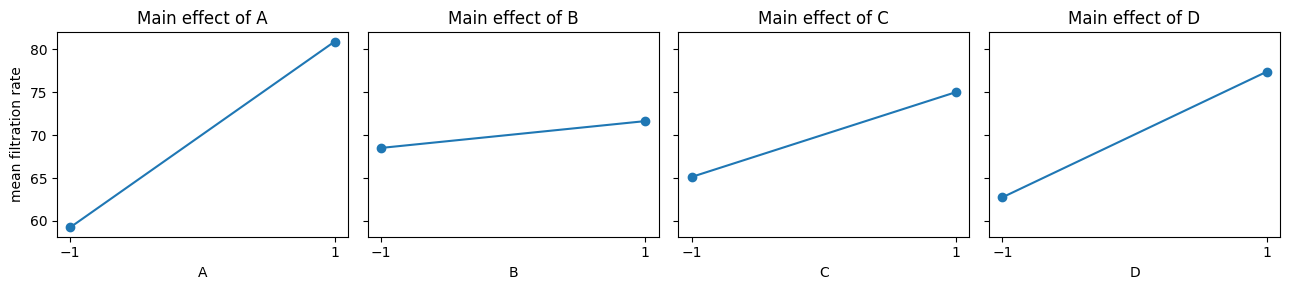

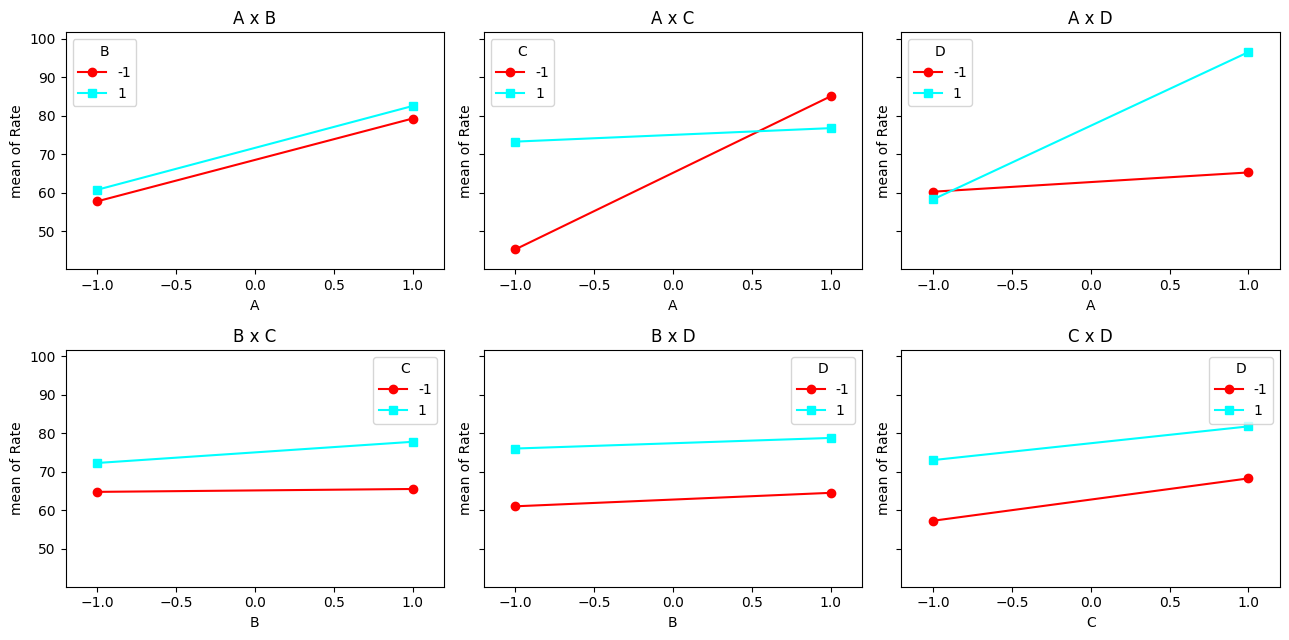

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for ax, f in zip(axes, factors):
    m = rate.groupby(f)["Rate"].mean()
    ax.plot(m.index, m.to_numpy(), "o-")
    ax.set(xticks=[-1, 1], xlabel=f, title=f"Main effect of {f}")
axes[0].set_ylabel("mean filtration rate")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharey=True)
for ax, (f1, f2) in zip(axes.flat, itertools.combinations(factors, 2)):
    interaction_plot(rate[f1], rate[f2], rate["Rate"], ax=ax, markers=["o", "s"])
    ax.set_title(f"{f1} x {f2}")
plt.tight_layout()
plt.show()

The plots suggest large main effects of $A$, $C$, $D$ and interactions $A \times C$ and $A \times D$. The lines of $B$ are
almost flat. But without an error estimate we cannot say which differences are larger than the noise.

### The full model has no error term

In [4]:
import warnings

full = smf.ols("Rate ~ A*B*C*D", data=rate).fit()
print("residual degrees of freedom:", full.df_resid)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)     # division by the zero residual df
    print(anova_lm(full).round(2))

residual degrees of freedom: 0.0
           df   sum_sq  mean_sq    F  PR(>F)
A         1.0  1870.56  1870.56  0.0     NaN
B         1.0    39.06    39.06  0.0     NaN
A:B       1.0     0.06     0.06  0.0     NaN
C         1.0   390.06   390.06  0.0     NaN
A:C       1.0  1314.06  1314.06  0.0     NaN
B:C       1.0    22.56    22.56  0.0     NaN
A:B:C     1.0    14.06    14.06  0.0     NaN
D         1.0   855.56   855.56  0.0     NaN
A:D       1.0  1105.56  1105.56  0.0     NaN
B:D       1.0     0.56     0.56  0.0     NaN
A:B:D     1.0    68.06    68.06  0.0     NaN
C:D       1.0     5.06     5.06  0.0     NaN
A:C:D     1.0    10.56    10.56  0.0     NaN
B:C:D     1.0    27.56    27.56  0.0     NaN
A:B:C:D   1.0     7.56     7.56  0.0     NaN
Residual  0.0     0.00      inf  NaN     NaN


16 observations, 16 parameters, 0 residual degrees of freedom. The sums of squares are correct, but **statsmodels prints
$F = 0$ and missing $p$-values: these are not test results.** We have to judge the effects without an estimate of $\sigma^2$.

### Effects from the table of signs

In [5]:
eff_table = effects_2k(rate, "Rate", factors)
eff = eff_table["effect"].rename(lambda t: t.replace(":", ""))      # names A, B, AB, ..., ABCD
eff_table.round(3)

,contrast,effect,SS,coef
term,,,,
A,173,21.625,1870.562,10.812
B,25,3.125,39.062,1.562
A:B,1,0.125,0.062,0.062
C,79,9.875,390.062,4.938
A:C,-145,-18.125,1314.062,-9.062
B:C,19,2.375,22.562,1.188
A:B:C,15,1.875,14.062,0.938
D,117,14.625,855.562,7.312
A:D,133,16.625,1105.562,8.312


In [6]:
# the effects are twice the regression coefficients of the full model
check = 2 * full.params.drop("Intercept")
np.allclose(check[eff_table.index], eff_table["effect"])

True

### Normal and half-normal plots of the effects

A negligible effect is $N(0, 4\sigma^2/N)$; the negligible effects lie on a straight line, the active effects are outliers.

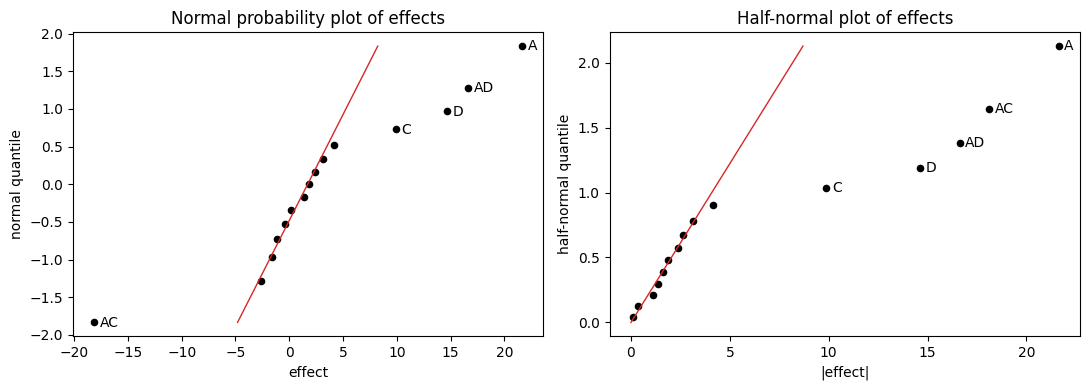

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(eff, ax=axes[0])
effect_plot(eff, half=True, ax=axes[1])
plt.tight_layout()
plt.show()

### Lenth's method and the Pareto plot

{'s0': 3.938, 'PSE': 2.625, 'ME': 6.748, 'SME': 13.699}
|effect| > ME:  ['A', 'C', 'AC', 'D', 'AD']
|effect| > SME: ['A', 'AC', 'D', 'AD']


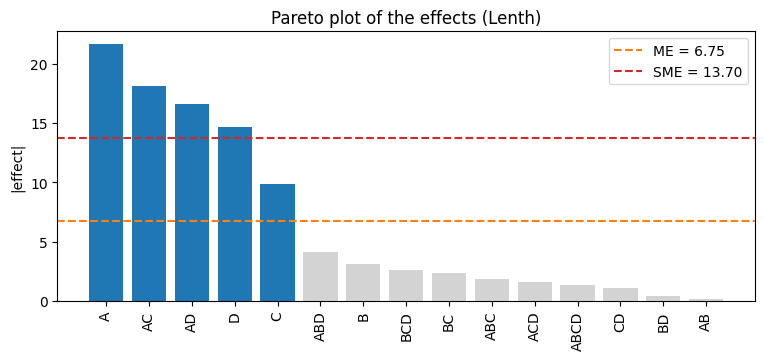

In [8]:
L = lenth(eff)
print({k: round(v, 3) for k, v in L.items()})
print("|effect| > ME: ", list(eff[eff.abs() > L["ME"]].index))
print("|effect| > SME:", list(eff[eff.abs() > L["SME"]].index))
pareto_plot(eff)
plt.show()

$PSE = 2.625$, $ME = 6.75$, $SME = 13.70$ (the same numbers as Montgomery). The effects $A$, $AC$, $AD$, $D$ exceed $SME$,
$C$ exceeds only $ME$. Because $AC$ is clearly active, we keep $C$ (hierarchy). The tentative model is
$A + C + D + AC + AD$; factor $B$ (pressure) does not appear at all.

### Projection into a replicated $2^3$ design

Dropping $B$ projects the single replicate of the $2^4$ into a $2^3$ design in $A$, $C$, $D$ with two replicates, so now
we have 8 degrees of freedom for pure error. (Last year's notebook built this design by stacking two copies of the $2^3$
table and pairing them with the observations in the wrong order. Fitting the model to the original data frame without $B$
avoids that mistake.)

In [9]:
m_acd = smf.ols("Rate ~ A*C*D", data=rate).fit()
anova_lm(m_acd)

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,1870.5625,1870.5625,83.367688,0.000017
C,1.0,390.0625,390.0625,17.384401,0.003124
A:C,1.0,1314.0625,1314.0625,58.565460,0.000060
D,1.0,855.5625,855.5625,38.130919,0.000267
A:D,1.0,1105.5625,1105.5625,49.272981,0.000110
C:D,1.0,5.0625,5.0625,0.225627,0.647483
A:C:D,1.0,10.5625,10.5625,0.470752,0.512032
Residual,8.0,179.5000,22.4375,NaN,NaN


In [10]:
final = smf.ols("Rate ~ A + C + D + A:C + A:D", data=rate).fit()
print(anova_lm(final).round(4))
print(final.summary().tables[1])
print(f"s = {np.sqrt(final.scale):.3f}, R2 = {final.rsquared:.4f}, R2_adj = {final.rsquared_adj:.4f}")

            df     sum_sq    mean_sq        F  PR(>F)
A          1.0  1870.5625  1870.5625  95.8648  0.0000
C          1.0   390.0625   390.0625  19.9904  0.0012
D          1.0   855.5625   855.5625  43.8469  0.0001
A:C        1.0  1314.0625  1314.0625  67.3447  0.0000
A:D        1.0  1105.5625  1105.5625  56.6592  0.0000
Residual  10.0   195.1250    19.5125      NaN     NaN
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     70.0625      1.104     63.444      0.000      67.602      72.523
A             10.8125      1.104      9.791      0.000       8.352      13.273
C              4.9375      1.104      4.471      0.001       2.477       7.398
D              7.3125      1.104      6.622      0.000       4.852       9.773
A:C           -9.0625      1.104     -8.206      0.000     -11.523      -6.602
A:D            8.3125      1.104      7.527      0.000       5.852   

C:\Users\Mateusz\AppData\Local\Programs\Python\Python311\Lib\site-packages\scipy\stats\_axis_nan_policy.py:418: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=16 observations were given.
  return hypotest_fun_in(*args, **kwds)


$$\hat y = 70.06 + 10.81\,x_1 + 4.94\,x_3 + 7.31\,x_4 - 9.06\,x_1x_3 + 8.31\,x_1x_4,$$
with $\hat\sigma = 4.42$ and $R^2 = 0.966$. The residual mean square 19.51 (10 df) is the pure error (8 df) plus the dropped
$CD$ and $ACD$ (2 df). Check the residuals, also against the dropped factor $B$:

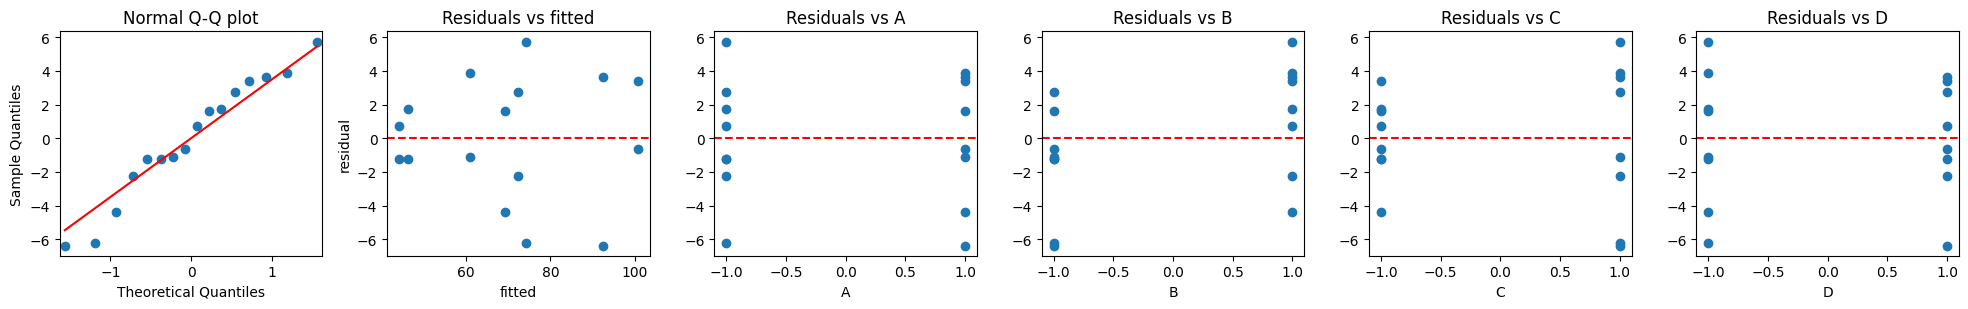

Shapiro-Wilk on residuals: ShapiroResult(statistic=0.9534713000836802, pvalue=0.546594438442996)


In [11]:
residual_plots(final, rate, factors)

### Contour plots and the best settings

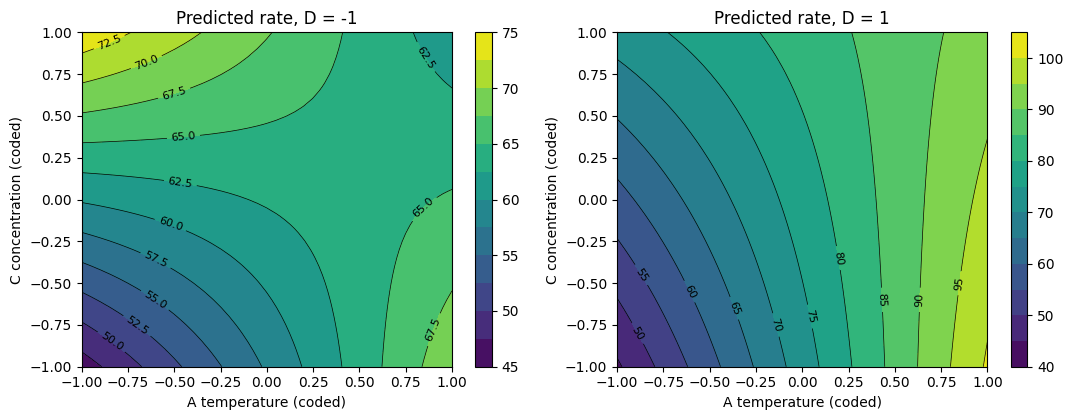

,A,C,D,predicted
5,1,-1,1,100.625
7,1,1,1,92.375
2,-1,1,-1,74.250


In [12]:
g = np.linspace(-1, 1, 41)
A, C = np.meshgrid(g, g)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, d in zip(axes, [-1, 1]):
    grid = pd.DataFrame({"A": A.ravel(), "C": C.ravel(), "D": d})
    Z = final.predict(grid).to_numpy().reshape(A.shape)
    cs = ax.contourf(A, C, Z, levels=12, cmap="viridis")
    ax.clabel(ax.contour(A, C, Z, levels=12, colors="k", linewidths=0.5), fontsize=8)
    fig.colorbar(cs, ax=ax)
    ax.set(xlabel="A temperature (coded)", ylabel="C concentration (coded)", title=f"Predicted rate, D = {d}")
plt.tight_layout()
plt.show()

corners = pd.DataFrame(list(itertools.product([-1, 1], repeat=3)), columns=["A", "C", "D"])
corners["predicted"] = final.predict(corners)
corners.sort_values("predicted", ascending=False).head(3)

The highest predicted filtration rate (100.6 gal/h) is at high temperature, low concentration of formaldehyde and high
stirring rate ($A = +$, $C = -$, $D = +$); pressure ($B$) can be set at the cheaper level. The model is linear with
interactions and should not be extrapolated outside the cube.

### Pooling only the highest-order interaction?

In [13]:
m_3way = smf.ols("Rate ~ (A + B + C + D)**3", data=rate).fit()
anova_lm(m_3way).round(4)

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,1870.5625,1870.5625,247.3471,0.0404
B,1.0,39.0625,39.0625,5.1653,0.2639
C,1.0,390.0625,390.0625,51.5785,0.0881
D,1.0,855.5625,855.5625,113.1322,0.0597
A:B,1.0,0.0625,0.0625,0.0083,0.9423
A:C,1.0,1314.0625,1314.0625,173.7603,0.0482
A:D,1.0,1105.5625,1105.5625,146.1901,0.0525
B:C,1.0,22.5625,22.5625,2.9835,0.3341
B:D,1.0,0.5625,0.5625,0.0744,0.8305
C:D,1.0,5.0625,5.0625,0.6694,0.5635


The error term is $ABCD$ with **one** degree of freedom, $F_{0.05,1,1} = 161.4$: even the large effects $C$, $D$ and
$AD$ are not significant. Such a test has almost no power; the normal plot / Lenth's method and the projection are better.

### The effect of an outlier

Suppose the run $cd$ was recorded as 375 instead of 75 (Montgomery, Section 6.5). The error of 300 enters every effect with
weight $\pm 300/8 = \pm 37.5$.

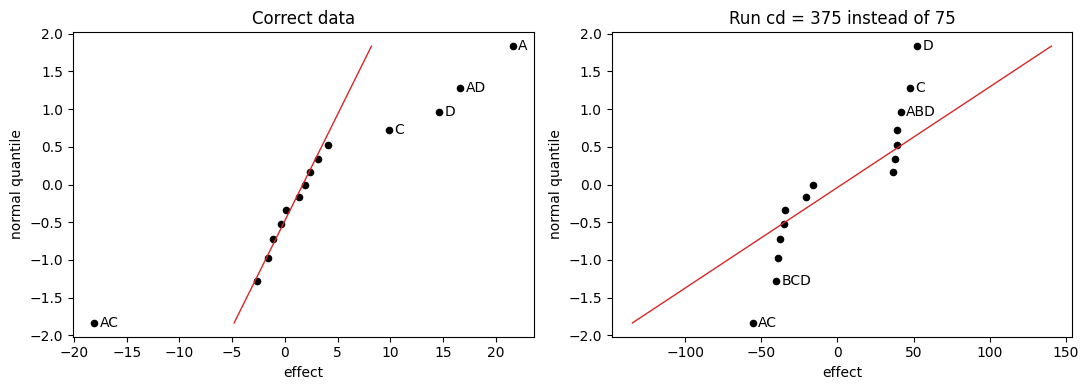

Lenth with the outlier: {'s0': 58.31, 'PSE': 58.31, 'ME': 149.9, 'SME': 304.31}


In [14]:
bad = rate.copy()
bad.loc[bad["label"] == "cd", "Rate"] = 375
eff_bad = effects_2k(bad, "Rate", factors)["effect"].rename(lambda t: t.replace(":", ""))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(eff, ax=axes[0], title="Correct data")
effect_plot(eff_bad, ax=axes[1], title="Run cd = 375 instead of 75")
plt.tight_layout()
plt.show()
print("Lenth with the outlier:", {k: round(v, 2) for k, v in lenth(eff_bad).items()})

The effects split into two groups around $\pm 37.5$ with a gap in the middle; there is no straight line through the small
effects and Lenth's method finds nothing. When the normal plot looks like this, check the data first.

----

## 2. Lecture example: data transformation (drill advance rate)

Montgomery, Example 6.3 (Daniel, 1976): a single replicate of a $2^4$ design for the advance rate of a drill. Factors: drill
load ($A$), flow rate ($B$), rotational speed ($C$) and type of drilling mud ($D$). The data are read from Figure 6.19 of the
book and entered in standard order.

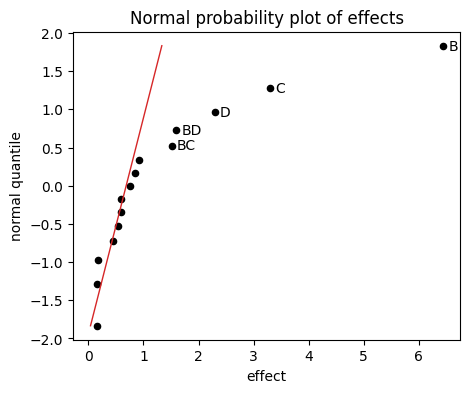

term
AC      0.155
ABC     0.163
BCD     0.175
CD      0.448
ABCD    0.543
ACD     0.585
AB      0.590
ABD     0.760
AD      0.838
A       0.918
BC      1.510
BD      1.592
D       2.290
C       3.293
B       6.438
Name: effect, dtype: float64

In [15]:
drill = pd.DataFrame([r[::-1] for r in itertools.product([-1, 1], repeat=4)], columns=factors)
drill["rate"] = [1.68, 1.98, 4.98, 5.70, 3.24, 3.44, 9.97, 9.07,
                 2.07, 2.44, 7.77, 9.43, 4.09, 4.53, 11.75, 16.30]
eff_drill = effects_2k(drill, "rate", factors)["effect"].rename(lambda t: t.replace(":", ""))
effect_plot(eff_drill)
plt.show()
eff_drill.sort_values().round(3)

On the original scale $B$, $C$, $D$ and the interactions $BC$, $BD$ look active. Fit this model and look at the residuals:

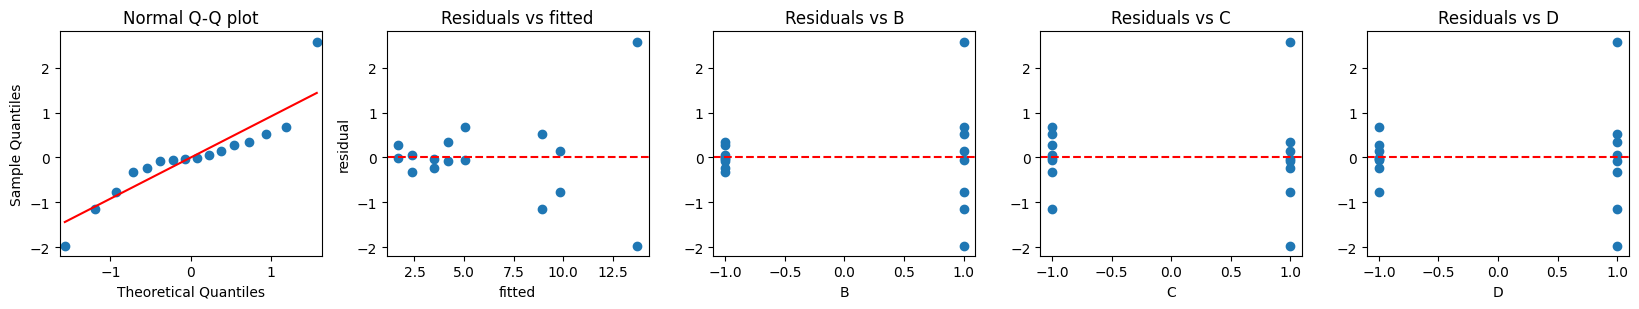

Shapiro-Wilk on residuals: ShapiroResult(statistic=0.8811859330110848, pvalue=0.04049249370392219)


In [16]:
m_raw = smf.ols("rate ~ B + C + D + B:C + B:D", data=drill).fit()
residual_plots(m_raw, drill, ["B", "C", "D"])

The residuals form a **funnel**: their spread grows with the predicted advance rate. The response is a rate, the effects are
likely multiplicative, so try the log transformation. A quick Box-Cox check: residual sum of squares of the model $B + C + D$
for the scaled power transformation $y^{(\lambda)} = (y^\lambda - 1)/(\lambda \dot y^{\lambda - 1})$ ($\dot y$ = geometric
mean, $\lambda = 0$: $\dot y \ln y$), so that the values are comparable across $\lambda$.

In [17]:
gm = np.exp(np.log(drill["rate"]).mean())
for lam in [1, 0.5, 0, -0.5, -1]:
    if lam == 0:
        y_lam = gm * np.log(drill["rate"])
    else:
        y_lam = (drill["rate"]**lam - 1) / (lam * gm**(lam - 1))
    ssr = smf.ols("y ~ B + C + D", data=drill.assign(y=y_lam)).fit().ssr
    print(f"lambda = {lam:5.1f}: residual SS = {ssr:6.2f}")

lambda =   1.0: residual SS =  32.81
lambda =   0.5: residual SS =  10.55
lambda =   0.0: residual SS =   4.21
lambda =  -0.5: residual SS =   7.87
lambda =  -1.0: residual SS =  23.26


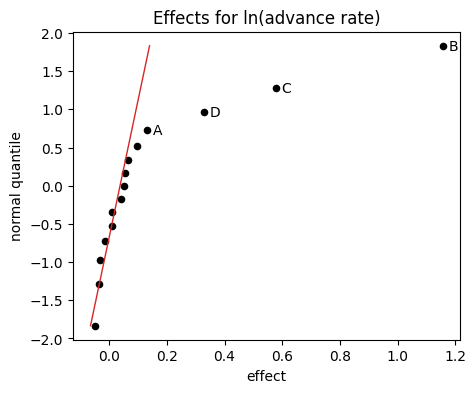

            df  sum_sq  mean_sq         F  PR(>F)
B          1.0  5.3452   5.3452  371.4928  0.0000
C          1.0  1.3389   1.3389   93.0517  0.0000
D          1.0  0.4305   0.4305   29.9224  0.0001
Residual  12.0  0.1727   0.0144       NaN     NaN
R2 = 0.9763


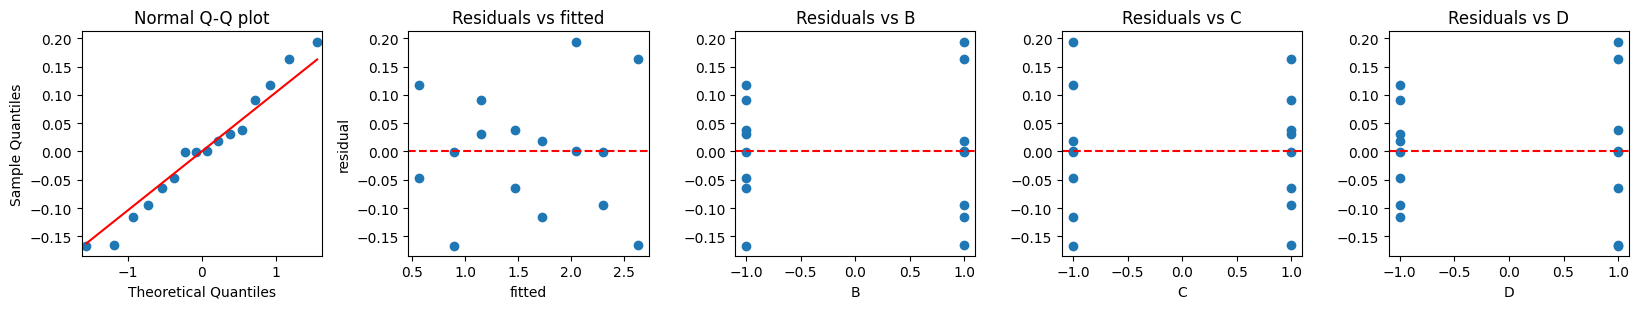

Shapiro-Wilk on residuals: ShapiroResult(statistic=0.9681448902399931, pvalue=0.8077359505482492)


In [18]:
drill["log_rate"] = np.log(drill["rate"])
eff_log = effects_2k(drill, "log_rate", factors)["effect"].rename(lambda t: t.replace(":", ""))
effect_plot(eff_log, n_label=4, title="Effects for ln(advance rate)")
plt.show()

m_log = smf.ols("log_rate ~ B + C + D", data=drill).fit()
print(anova_lm(m_log).round(4))
print(f"R2 = {m_log.rsquared:.4f}")
residual_plots(m_log, drill, ["B", "C", "D"])

After the log transformation only the main effects $B$, $C$, $D$ are active, the interactions disappeared and the residuals
look fine ($R^2 = 0.976$). Predictions are computed on the log scale and transformed back with `np.exp` (this estimates
the median of the advance rate):

In [19]:
new = pd.DataFrame({"B": [1], "C": [1], "D": [1]})
print("predicted advance rate at B = C = D = +1:", np.exp(m_log.predict(new)).round(2).iloc[0])

predicted advance rate at B = C = D = +1: 13.85


----

## 3. Lecture example: location and dispersion effects (panel process)

Montgomery, Example 6.4: a single replicate of a $2^4$ design in a process producing interior panels for aircraft. Response:
the average number of defects per panel in a press load. Factors: temperature $A$ (295, 325 $^\circ$F), clamp time $B$
(7, 9 min), resin flow $C$ (10, 20), closing time $D$ (15, 30 s). Data from Figure 6.26 of the book, in standard order.

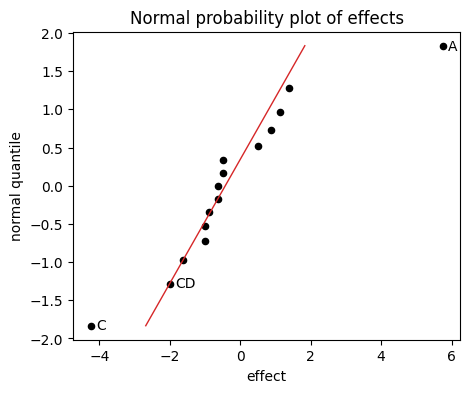

Intercept    6.688
A            2.875
C           -2.125
dtype: float64 R2 = 0.775


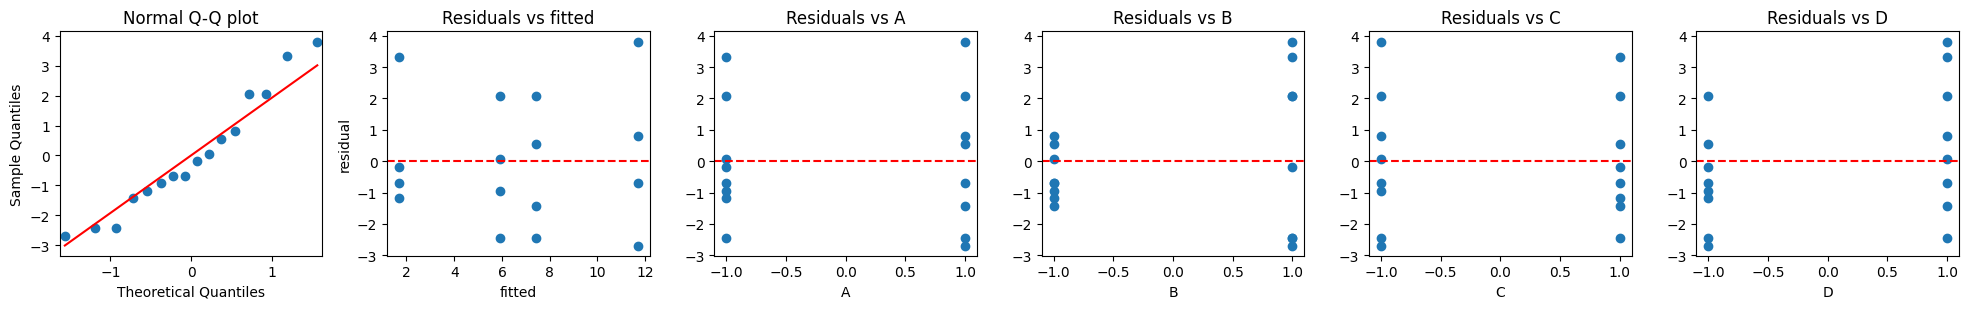

Shapiro-Wilk on residuals: ShapiroResult(statistic=0.9427968214827388, pvalue=0.3846952932748428)


In [20]:
panel = pd.DataFrame([r[::-1] for r in itertools.product([-1, 1], repeat=4)], columns=factors)
panel["defects"] = [5, 11, 3.5, 9, 0.5, 8, 1.5, 9.5, 6, 12.5, 8, 15.5, 1, 6, 5, 5]
eff_panel = effects_2k(panel, "defects", factors)["effect"].rename(lambda t: t.replace(":", ""))
effect_plot(eff_panel, n_label=3)
plt.show()

m_loc = smf.ols("defects ~ A + C", data=panel).fit()
print(m_loc.params.round(3), f"R2 = {m_loc.rsquared:.3f}")
residual_plots(m_loc, panel, factors)

Location effects: $A = 5.75$ and $C = -4.25$, so low temperature and high resin flow reduce the number of defects. The plot
of the residuals against $B$ (clamp time) shows a much larger spread at the high level of $B$. For every column of the table
of signs we compute the **dispersion effect**
$$F_i^* = \ln \frac{S^2(i^+)}{S^2(i^-)},$$
where $S(i^\pm)$ is the standard deviation of the residuals at the runs where the column is $\pm$.

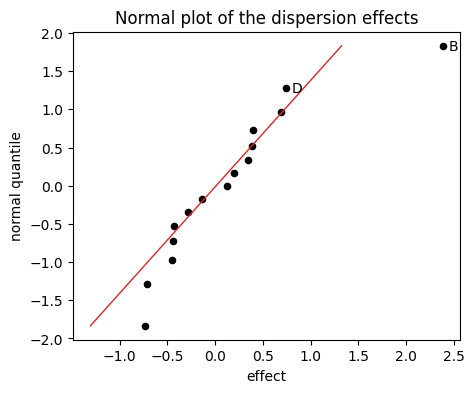

ABCD   -0.74
ACD    -0.71
BC     -0.45
ABC    -0.44
AC     -0.43
C      -0.29
ABD    -0.14
AD      0.13
BCD     0.20
AB      0.35
A       0.39
CD      0.40
BD      0.69
D       0.74
B       2.39
dtype: float64

In [21]:
e = m_loc.resid
Fstar = {}
for t in eff_panel.index:
    s = panel[list(t)].prod(axis=1)
    Fstar[t] = np.log(e[s == 1].var() / e[s == -1].var())
Fstar = pd.Series(Fstar)
effect_plot(Fstar, n_label=2, title="Normal plot of the dispersion effects")
plt.show()
Fstar.sort_values().round(2)

$F_B^* = 2.39$ stands out: clamp time does not change the mean number of defects, but the low clamp time gives a smaller
variability. Recommended: low temperature and high resin flow (location), low clamp time (dispersion).

----

## Assignment

Work on the assignment in class (in pairs, if you like). Whatever you do not finish in class, finish at home as homework.

* Run the notebook above and make sure you understand each step.
* Solve the following problems from Montgomery, *Design and Analysis of Experiments* (8th edition): **6.17, 6.28 with 6.29,
  6.31 with 6.32 and 6.36**; Problem 6.30 is optional.
* Use the normal (or half-normal) plot of the effects together with Lenth's method to choose the model, respect the
  hierarchy, state the hypotheses, the test statistic, its $p$-value and your decision for the final model, check the
  residuals and end each problem with a conclusion in one or two sentences.
* Submit your solved notebook as a pull request into the `HW/` folder of the course repository, named
  `HW/01NAEX_Ex06_HW_<Surname>.ipynb` (see `HW/README.md`). **Deadline: Sunday 8 November 2026** (the next lecture is on
  9 November; Team Project 1 has the same deadline).

### Problem 6.17

An experimenter has run a single replicate of a $2^4$ design. The following effect estimates have been calculated:

| Effect | Estimate | Effect | Estimate | Effect | Estimate |
|---|---|---|---|---|---|
| $A$ | 76.95 | $AB$ | $-51.32$ | $ABC$ | $-2.82$ |
| $B$ | $-67.52$ | $AC$ | 11.69 | $ABD$ | $-6.50$ |
| $C$ | $-7.84$ | $AD$ | 9.78 | $ACD$ | 10.20 |
| $D$ | $-18.73$ | $BC$ | 20.78 | $BCD$ | $-7.98$ |
| | | $BD$ | 14.74 | $ABCD$ | $-6.25$ |
| | | $CD$ | 1.27 | | |

(a) Construct a normal probability plot of these effects.

(b) Identify a tentative model, based on the plot of the effects in part (a).

(c) (Added.) Apply Lenth's method. Does it lead to the same model?

**Solution:**

**(a) Normal probability plot.** Only the 15 effect estimates are given ($N = 16$). A negligible effect is approximately
$N(0, 4\sigma^2/N)$, so the negligible effects fall on a straight line through the origin and the active ones leave it. The
line is fitted through the smaller half of the effects (`effect_plot()`); the half-normal plot is shown next to it.

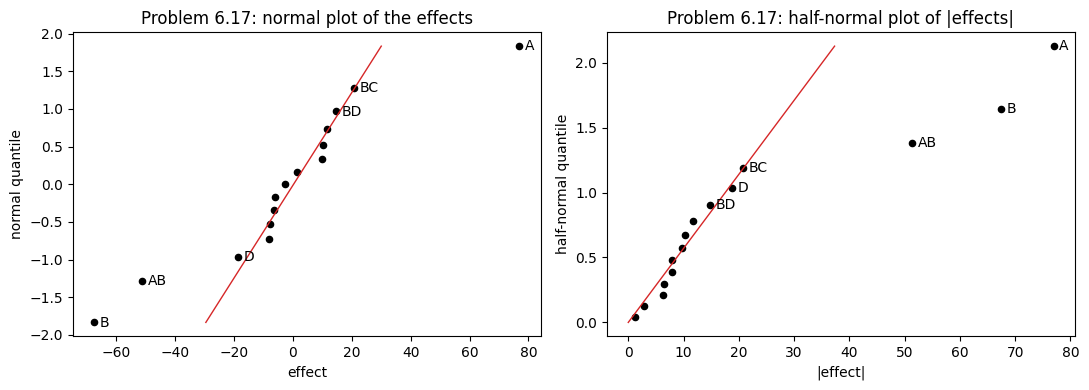

B      -67.52
AB     -51.32
D      -18.73
BCD     -7.98
C       -7.84
ABD     -6.50
ABCD    -6.25
ABC     -2.82
CD       1.27
AD       9.78
ACD     10.20
AC      11.69
BD      14.74
BC      20.78
A       76.95


In [22]:
# 6.17a: the given effect estimates and their normal / half-normal probability plots
import warnings
warnings.filterwarnings("ignore", message=".*kurtosistest.*")     # small-sample note printed by model.summary()
e617 = pd.Series({"A": 76.95, "B": -67.52, "C": -7.84, "D": -18.73,
                  "AB": -51.32, "AC": 11.69, "AD": 9.78, "BC": 20.78, "BD": 14.74, "CD": 1.27,
                  "ABC": -2.82, "ABD": -6.50, "ACD": 10.20, "BCD": -7.98, "ABCD": -6.25})
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(e617, n_label=6, ax=axes[0], title="Problem 6.17: normal plot of the effects")
effect_plot(e617, half=True, n_label=6, ax=axes[1], title="Problem 6.17: half-normal plot of |effects|")
plt.tight_layout(); plt.show()
print(e617.sort_values().to_string())

Three points leave the line: $A = 76.95$, $B = -67.52$ and $AB = -51.32$. The other twelve effects (from $CD = 1.27$ to
$BC = 20.78$ in absolute value) lie on the line, whose slope (about 16) estimates the standard deviation of a negligible effect.

**(b) Tentative model.** $A$, $B$ and $AB$; hierarchical as it stands:
$$\hat y = \bar y + 38.48\,x_1 - 33.76\,x_2 - 25.66\,x_1 x_2$$
(coefficients = effects / 2, $\bar y$ not given). $C$ and $D$ drop out, so the design projects into a $2^2$ in $A$, $B$ with
four replicates. Because of $AB$ the factors must be read together: the effect of $A$ is $A - AB = 128.3$ at low $B$ and
$A + AB = 25.6$ at high $B$.

**(c) Lenth's method.** $s_0 = 1.5 \cdot \text{median}|c_j|$, $PSE = 1.5 \cdot \text{median}\{|c_j| : |c_j| < 2.5\,s_0\}$,
$ME = t_{0.025,\,m/3}\,PSE$, $SME = t_{\gamma,\,m/3}\,PSE$ with $\gamma = (1 + 0.95^{1/m})/2$, $m = 15$. $H_0$: effect $= 0$
is rejected when $|c_j| > ME$ (individually) or $|c_j| > SME$ (simultaneously); $c_j / PSE$ is a $t$-like statistic with
5 df. As a second check the twelve negligible effects are pooled: $SS_j = N c_j^2/4 = 4 c_j^2$, $MS_E = \sum SS_j / 12$,
$F_0 = SS_j / MS_E$ with $(1, 12)$ df.

median |effect| = 10.20, s0 = 15.30, 2.5 s0 = 38.25, effects kept for PSE: 12, their median = 8.88
{'s0': 15.3, 'PSE': 13.32, 'ME': 34.24, 'SME': 69.512}
|effect| > ME : ['A', 'B', 'AB']
|effect| > SME: ['A']


,effect,effect / PSE,"p (t, 5 df)"
A,76.95,5.78,0.0022
B,-67.52,-5.07,0.0039
AB,-51.32,-3.85,0.0120
BC,20.78,1.56,0.1795
D,-18.73,-1.41,0.2187
BD,14.74,1.11,0.3188
AC,11.69,0.88,0.4203
ACD,10.20,0.77,0.4784


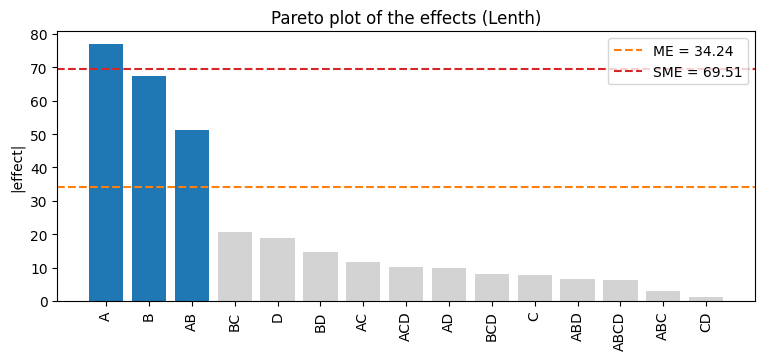

In [23]:
# 6.17c: Lenth's method, the t-like ratios effect / PSE and the Pareto plot
L617 = lenth(e617)
print(f"median |effect| = {e617.abs().median():.2f}, s0 = {L617['s0']:.2f}, 2.5 s0 = {2.5 * L617['s0']:.2f}, "
      f"effects kept for PSE: {int((e617.abs() < 2.5 * L617['s0']).sum())}, their median = "
      f"{e617.abs()[e617.abs() < 2.5 * L617['s0']].median():.2f}")
print({k: round(v, 3) for k, v in L617.items()})
print("|effect| > ME :", list(e617[e617.abs() > L617["ME"]].index))
print("|effect| > SME:", list(e617[e617.abs() > L617["SME"]].index))
lenth_tab = pd.DataFrame({"effect": e617, "effect / PSE": (e617 / L617["PSE"]).round(2),
                          "p (t, 5 df)": (2 * stats.t.sf(np.abs(e617 / L617["PSE"]), df=len(e617) / 3)).round(4)})
display(lenth_tab.sort_values("effect / PSE", key=np.abs, ascending=False).head(8))
pareto_plot(e617); plt.show()

In [24]:
# 6.17c (cont.): the twelve negligible effects pooled into an error term with 12 df
active = ["A", "B", "AB"]
SS617 = 4 * e617**2                       # SS_j = N c_j^2 / 4 with N = 16
MSE617 = SS617.drop(active).sum() / 12
se_eff = np.sqrt(4 * MSE617 / 16)        # se of an effect = sqrt(4 MS_E / N)
F0 = SS617[active] / MSE617
display(pd.DataFrame({"effect": e617[active], "SS": SS617[active].round(1), "F0 (1, 12 df)": F0.round(2),
                      "p-value": stats.f.sf(F0, 1, 12)}))
print(f"MS_E (12 df) = {MSE617:.2f}, se(effect) = {se_eff:.2f}  (Lenth PSE = {L617['PSE']:.2f})")
for t in ["BC", "D"]:
    t0 = e617[t] / se_eff
    print(f"next candidate {t:>2}: t0 = {t0:6.2f}, p = {2 * stats.t.sf(abs(t0), 12):.3f}")

,effect,SS,"F0 (1, 12 df)",p-value
A,76.95,23685.2,45.78,0.000020
B,-67.52,18235.8,35.24,0.000069
AB,-51.32,10535.0,20.36,0.000711


MS_E (12 df) = 517.42, se(effect) = 11.37  (Lenth PSE = 13.32)
next candidate BC: t0 =   1.83, p = 0.093
next candidate  D: t0 =  -1.65, p = 0.126


Median $|c_j| = 10.20$, $s_0 = 15.30$; $2.5\,s_0 = 38.25$ removes exactly $A$, $B$, $AB$; the median of the other twelve is
8.88, so $PSE = 13.32$, $ME = 34.2$, $SME = 69.5$.

| Effect | Estimate | $c_j / PSE$ | vs $ME = 34.2$ | vs $SME = 69.5$ | Decision |
|---|---|---|---|---|---|
| $A$ | 76.95 | 5.78 | above | above | active |
| $B$ | $-67.52$ | $-5.07$ | above | below | active |
| $AB$ | $-51.32$ | $-3.85$ | above | below | active |
| $BC$ | 20.78 | 1.56 | below | below | negligible |

Lenth's method gives the same model as the plot: $A$, $B$, $AB$ exceed $ME$, the next effect $BC$ has $p = 0.18$. $B$ falls
just short of the simultaneous limit, which does not change the model. The pooled 12-df error gives $MS_E = 517.4$,
$se(\text{effect}) = 11.4$ (Lenth: 13.3), $p < 0.0001$ for $A$ and $B$, $p = 0.0007$ for $AB$ and $p = 0.09$ for $BC$.
$PSE$ corresponds to $\hat\sigma \approx 27$.

**Conclusions (Problem 6.17)**

* The normal plot and Lenth's method ($ME = 34.2$) agree: $A$, $B$ and $AB$ are active, all with $p \le 0.0007$ against the
  pooled error; the twelve other effects are noise.
* Tentative model $\hat y = \bar y + 38.5\,x_1 - 33.8\,x_2 - 25.7\,x_1 x_2$; $A$ raises the response by about 128 at low $B$
  but only by 26 at high $B$.

### Problems 6.28 and 6.29: process development (yield)

In a process development study on yield, four factors were studied, each at two levels: time ($A$: 2.5 and 3 h),
concentration ($B$: 14 and 18 %), pressure ($C$: 60 and 80 psi) and temperature ($D$: 225 and 250 $^\circ$C). A single
replicate of a $2^4$ design was run. The file `Problem_6_28.csv` contains the factor levels in natural units and the
yield (lbs) in standard order (the actual run order is given in Table P6.7 of the book).

In [25]:
p628 = pd.read_csv(URL + "Problem_6_28.csv")
p628

,Time,Concentration,Pressure,Temperature,Yield
0,2.5,14,60,225,12
1,3.0,14,60,225,18
2,2.5,18,60,225,13
3,3.0,18,60,225,16
4,2.5,14,80,225,17
5,3.0,14,80,225,15
6,2.5,18,80,225,20
7,3.0,18,80,225,15
8,2.5,14,60,250,10
9,3.0,14,60,250,25


**Problem 6.28**

(a) Construct a normal probability plot of the effect estimates. Which factors appear to have large effects?

(b) Conduct an analysis of variance using the normal probability plot in part (a) for guidance in forming an error term.
What are your conclusions?

(c) Write down a regression model relating yield to the important process variables.

(d) Analyze the residuals from this experiment. Does your analysis indicate any potential problems?

(e) Can this design be collapsed into a $2^3$ design with two replicates? If so, sketch the design with the average and range
of yield shown at each point in the cube. Interpret the results.

Hint: first code the factors to $-1$/$+1$, for example `np.where(p628["Time"] == 3, 1, -1)`.

**Solution:**

**(a) Coding and normal plot.** $x_j = \pm 1$ at the low/high level: $A$ time ($x_1 = (\text{Time} - 2.75)/0.25$),
$B$ concentration, $C$ pressure ($x_3 = (\text{Pressure} - 70)/10$), $D$ temperature ($x_4 = (\text{Temp} - 237.5)/12.5$).
Effects from the table of signs; a negligible effect has variance $\sigma^2/4$, so the negligible effects form a straight line.
Lenth's method with $m = 15$, $\alpha = 0.05$.

term,A,B,A:B,C,A:C,B:C,A:B:C,D,A:D,B:D,A:B:D,C:D,A:C:D,B:C:D,A:B:C:D
effect,4.50,0.50,-0.750,2.0,-4.250,0.250,1.0,3.250,4.0,0.0,0.750,0.0,-0.250,-0.750,1.0
SS,81.00,1.00,2.250,16.0,72.250,0.250,4.0,42.250,64.0,0.0,2.250,0.0,0.250,2.250,4.0
coef,2.25,0.25,-0.375,1.0,-2.125,0.125,0.5,1.625,2.0,0.0,0.375,0.0,-0.125,-0.375,0.5


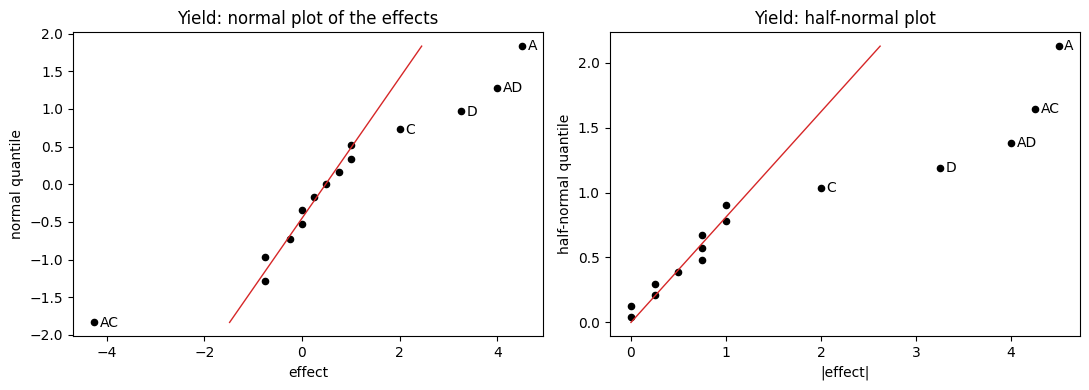

{'s0': 1.125, 'PSE': 1.125, 'ME': 2.892, 'SME': 5.871}
|effect| > ME : ['A', 'AC', 'D', 'AD']    |effect| > SME: []
|effect| / PSE: {'A': 4.0, 'AC': 3.78, 'AD': 3.56, 'D': 2.89, 'C': 1.78, 'ABC': 0.89}


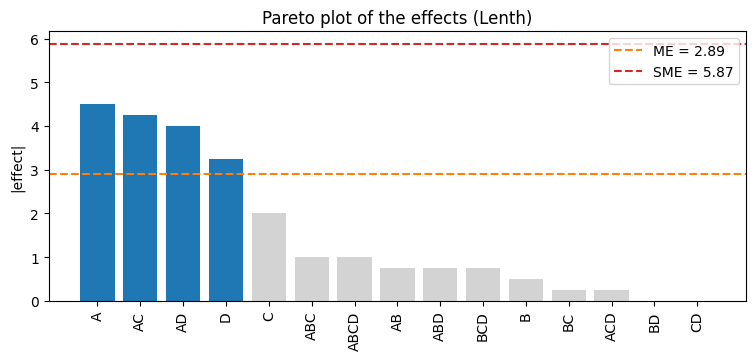

In [26]:
# 6.28a: coded factors, effect estimates, normal / half-normal plots and Lenth's method
p628["A"] = np.where(p628["Time"] == 3, 1, -1)
p628["B"] = np.where(p628["Concentration"] == 18, 1, -1)
p628["C"] = np.where(p628["Pressure"] == 80, 1, -1)
p628["D"] = np.where(p628["Temperature"] == 250, 1, -1)
F4 = list("ABCD")
t628 = effects_2k(p628, "Yield", F4)
e628 = t628["effect"].rename(lambda t: t.replace(":", ""))
display(t628[["effect", "SS", "coef"]].round(3).T)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(e628, n_label=5, ax=axes[0], title="Yield: normal plot of the effects")
effect_plot(e628, half=True, n_label=5, ax=axes[1], title="Yield: half-normal plot")
plt.tight_layout(); plt.show()
L628 = lenth(e628)
print({k: round(v, 3) for k, v in L628.items()})
print("|effect| > ME :", list(e628[e628.abs() > L628["ME"]].index), "   |effect| > SME:", list(e628[e628.abs() > L628["SME"]].index))
print("|effect| / PSE:", (e628.abs() / L628["PSE"]).sort_values(ascending=False).round(2).head(6).to_dict())
pareto_plot(e628); plt.show()

Four effects leave the line: $A = 4.50$, $AD = 4.00$, $D = 3.25$ and $AC = -4.25$. $C = 2.00$ is borderline, everything else
is at most 1.0 in absolute value. Lenth: $PSE = 1.125$, $ME = 2.89$, $SME = 5.87$; $A$, $AC$, $AD$, $D$ exceed $ME$, $C$ does
not ($1.78\,PSE$) but is kept because $AC$ is active (hierarchy). Concentration $B$ has no effect at all.

**(b) ANOVA with a pooled error.** Error = the ten negligible effects ($B$ and all interactions except $AC$, $AD$; 10 df),
model `Yield ~ A + C + D + A:C + A:D`. For each term $H_0$: effect $= 0$, $F_0 = MS_{\text{term}}/MS_E$ with $(1, 10)$ df,
$\alpha = 0.05$. For comparison: error from the three- and four-factor interactions only (5 df).

In [27]:
# 6.28b: ANOVA of the tentative model, error = the ten negligible effects; comparison with pooling 3fi + 4fi only
m628 = smf.ols("Yield ~ A + C + D + A:C + A:D", data=p628).fit()
display(anova_lm(m628).round(4))
print(f"MS_E = {m628.mse_resid:.4f} ({m628.df_resid:.0f} df), s = {np.sqrt(m628.mse_resid):.3f}, "
      f"R2 = {m628.rsquared:.4f}, adj. R2 = {m628.rsquared_adj:.4f}")
m628_2fi = smf.ols("Yield ~ (A + B + C + D)**2", data=p628).fit()
print("\nAll main effects and two-factor interactions, error = three- and four-factor interactions (5 df):")
display(anova_lm(m628_2fi).round(4))

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,81.00,81.000,49.8462,0.0000
C,1.0,16.00,16.000,9.8462,0.0105
D,1.0,42.25,42.250,26.0000,0.0005
A:C,1.0,72.25,72.250,44.4615,0.0001
A:D,1.0,64.00,64.000,39.3846,0.0001
Residual,10.0,16.25,1.625,NaN,NaN


MS_E = 1.6250 (10 df), s = 1.275, R2 = 0.9443, adj. R2 = 0.9165

All main effects and two-factor interactions, error = three- and four-factor interactions (5 df):


,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,81.00,81.00,31.7647,0.0024
B,1.0,1.00,1.00,0.3922,0.5586
C,1.0,16.00,16.00,6.2745,0.0542
D,1.0,42.25,42.25,16.5686,0.0096
A:B,1.0,2.25,2.25,0.8824,0.3907
A:C,1.0,72.25,72.25,28.3333,0.0031
A:D,1.0,64.00,64.00,25.0980,0.0041
B:C,1.0,0.25,0.25,0.0980,0.7668
B:D,1.0,0.00,0.00,0.0000,1.0000
C:D,1.0,0.00,0.00,0.0000,1.0000


| Term | $SS$ | $F_0$ (1, 10 df) | $p$-value | Decision |
|---|---|---|---|---|
| $A$ time | 81.00 | 49.85 | $< 0.0001$ | reject $H_0$ |
| $C$ pressure | 16.00 | 9.85 | 0.0105 | reject $H_0$ |
| $D$ temperature | 42.25 | 26.00 | 0.0005 | reject $H_0$ |
| $AC$ | 72.25 | 44.46 | 0.0001 | reject $H_0$ |
| $AD$ | 64.00 | 39.38 | 0.0001 | reject $H_0$ |

All five terms are significant with $MS_E = 1.625$ (10 df). With only the 3fi + 4fi pooled (5 df, $MS_E = 2.55$) the picture
is the same but weaker: $C$ has $p = 0.054$, $B$ has $p = 0.56$. Time, temperature and pressure matter, the effects of pressure
and temperature depend on the time, concentration can be dropped.

**(c) Regression model.** Coded coefficients = effects / 2; the same model is refitted in natural units.

In [28]:
# 6.28c: regression model in coded units and in natural units
print(m628.summary().tables[1])
b = m628.params
print(f"\ncoded:   yhat = {b['Intercept']:.3f} + {b['A']:.3f} x1 + {b['C']:.3f} x3 + {b['D']:.3f} x4 "
      f"{b['A:C']:+.3f} x1 x3 {b['A:D']:+.3f} x1 x4")
m628_nat = smf.ols("Yield ~ Time + Pressure + Temperature + Time:Pressure + Time:Temperature", data=p628).fit()
print("natural:", {k: round(v, 4) for k, v in m628_nat.params.items()})
print("same fitted values as the coded model:", np.allclose(m628_nat.fittedvalues, m628.fittedvalues))

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     17.3750      0.319     54.520      0.000      16.665      18.085
A              2.2500      0.319      7.060      0.000       1.540       2.960
C              1.0000      0.319      3.138      0.011       0.290       1.710
D              1.6250      0.319      5.099      0.000       0.915       2.335
A:C           -2.1250      0.319     -6.668      0.000      -2.835      -1.415
A:D            2.0000      0.319      6.276      0.000       1.290       2.710

coded:   yhat = 17.375 + 2.250 x1 + 1.000 x3 + 1.625 x4 -2.125 x1 x3 +2.000 x1 x4
natural: {'Intercept': 209.125, 'Time': -83.5, 'Pressure': 2.4375, 'Temperature': -1.63, 'Time:Pressure': -0.85, 'Time:Temperature': 0.64}
same fitted values as the coded model: True


$$\hat y = 17.375 + 2.25\,x_1 + 1.00\,x_3 + 1.625\,x_4 - 2.125\,x_1 x_3 + 2.00\,x_1 x_4,$$
$R^2 = 0.944$, adjusted $R^2 = 0.917$, $\hat\sigma = 1.27$ lbs, $se(\hat\beta_j) = 0.319$. In natural units:
$\hat y = 209.1 - 83.5\,\text{Time} + 2.44\,\text{Pressure} - 1.63\,\text{Temp} - 0.85\,\text{Time} \cdot \text{Pressure} + 0.64\,\text{Time} \cdot \text{Temp}$;
the coded form is the one to interpret.

**(d) Residual analysis.** Q-Q plot, residuals against the fitted values and all four factors (including the dropped $B$),
Shapiro-Wilk test.

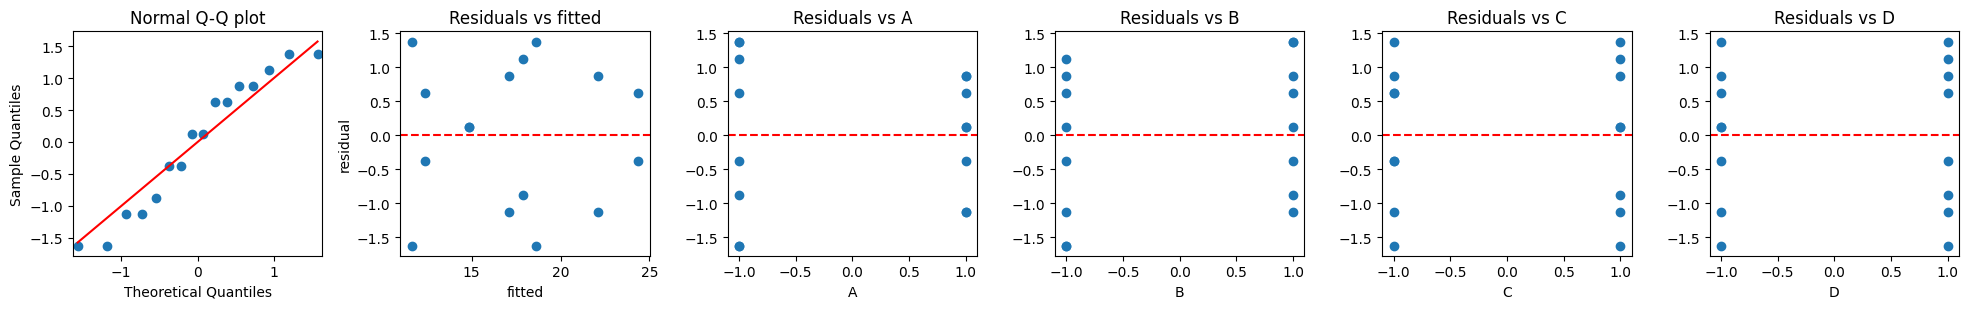

Shapiro-Wilk on residuals: ShapiroResult(statistic=0.9226963060387271, pvalue=0.1863876999074986)
residuals: [-0.375  0.875  0.625 -1.125 -1.625  0.125  1.375  0.125 -1.625  0.625
  1.375 -0.375  1.125 -1.125 -0.875  0.875]
residual variance at B = -1 / B = +1: 1.232 / 0.946


In [29]:
# 6.28d: residual analysis of the model A + C + D + AC + AD
residual_plots(m628, p628, F4)
print("residuals:", m628.resid.round(3).to_numpy())
print("residual variance at B = -1 / B = +1:", round(m628.resid[p628["B"] == -1].var(), 3), "/",
      round(m628.resid[p628["B"] == 1].var(), 3))

The residuals are multiples of 0.125 (integer yields), which gives the Q-Q plot a stepped look, but it is straight
(Shapiro-Wilk $W = 0.923$, $p = 0.19$). No funnel against the fitted values, equal spread at both levels of the dropped $B$
(variances 1.23 and 0.95), no pattern against $A$, $C$, $D$. No problems.

**(e) Collapsing into a $2^3$ with two replicates.** $B$ is inert, so the two runs differing only in $B$ are replicates of
the same $(A, C, D)$ treatment: a $2^3$ in time, pressure and temperature with $n = 2$ and 8 df of pure error. Cube with mean
and range per corner, full $A \times C \times D$ ANOVA, lack-of-fit test of the model from (c).

mean  min  max  range
A  C  D                        
-1 -1 -1  12.5   12   13      1
       1  11.5   10   13      3
    1 -1  18.5   17   20      3
       1  18.0   17   19      2
 1 -1 -1  17.0   16   18      2
       1  24.5   24   25      1
    1 -1  15.0   15   15      0
       1  22.0   21   23      2

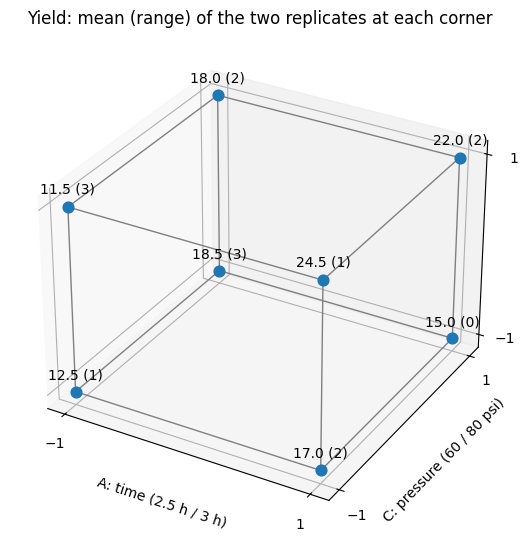

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,81.00,81.00,40.500,0.0002
C,1.0,16.00,16.00,8.000,0.0222
A:C,1.0,72.25,72.25,36.125,0.0003
D,1.0,42.25,42.25,21.125,0.0018
A:D,1.0,64.00,64.00,32.000,0.0005
C:D,1.0,0.00,0.00,0.000,1.0000
A:C:D,1.0,0.25,0.25,0.125,0.7328
Residual,8.0,16.00,2.00,NaN,NaN


lack of fit of the reduced model A + C + D + AC + AD against the full 2^3 model:


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,10.0,16.25,0.0,NaN,NaN,NaN
1,8.0,16.00,2.0,0.25,0.0625,0.9399


In [30]:
# 6.28e: projection into the 2^3 design in A, C, D with n = 2: cube with mean (range), ANOVA with pure error, lack of fit
cube = p628.groupby(["A", "C", "D"])["Yield"].agg(["mean", "min", "max"])
cube["range"] = cube["max"] - cube["min"]
display(cube)

fig = plt.figure(figsize=(7.5, 6.5))
ax = fig.add_subplot(111, projection="3d")
for (a, c, d), r in cube.iterrows():
    ax.scatter(a, c, d, color="tab:blue", s=60)
    ax.text(a, c, d + 0.15, f"{r['mean']:.1f} ({r['range']:.0f})", ha="center", fontsize=10)
for (x0, y0, z0), (x1, y1, z1) in itertools.combinations(itertools.product([-1, 1], repeat=3), 2):
    if (x0 != x1) + (y0 != y1) + (z0 != z1) == 1:
        ax.plot([x0, x1], [y0, y1], [z0, z1], color="gray", lw=1)
ax.set(xlabel="A: time (2.5 h / 3 h)", ylabel="C: pressure (60 / 80 psi)", zlabel="D: temperature (225 / 250 C)",
       xticks=[-1, 1], yticks=[-1, 1], zticks=[-1, 1], title="Yield: mean (range) of the two replicates at each corner")
plt.show()

m628_acd = smf.ols("Yield ~ A * C * D", data=p628).fit()
display(anova_lm(m628_acd).round(4))
print("lack of fit of the reduced model A + C + D + AC + AD against the full 2^3 model:")
display(anova_lm(m628, m628_acd).round(4))

The replicate ranges are 0 to 3 lbs against corner means from 11.5 to 24.5, so $B$ behaves like a replicate. Pure error
$MS_E = 2.00$ (8 df) agrees with the pooled 1.625; $A$ ($p = 0.0002$), $AC$ ($0.0003$), $AD$ ($0.0005$), $D$ ($0.0018$) and
$C$ ($0.022$) are significant, $CD$ and $ACD$ are not ($p = 1.0$, $0.73$); no lack of fit ($F_0 = 0.06$, $p = 0.94$). In the
cube: at 2.5 h the temperature does nothing and high pressure adds 6 lbs; at 3 h high temperature adds 7 lbs and high pressure
costs 2 lbs. Best corner: 3 h, 60 psi, 250 C, mean 24.5 lbs.

**Conclusions (Problem 6.28)**

* Active: $A$, $D$, $AC$, $AD$ (Lenth $ME = 2.89$), $C$ kept for hierarchy and significant ($p = 0.011$); $B$ has no effect.
* $\hat y = 17.38 + 2.25\,x_1 + 1.00\,x_3 + 1.63\,x_4 - 2.13\,x_1 x_3 + 2.00\,x_1 x_4$, $R^2 = 0.94$, residuals fine.
* The design collapses into a replicated $2^3$ in $A$, $C$, $D$ (pure $MS_E = 2.0$, no lack of fit); maximum yield 24.5 lbs
  at 3 h, 60 psi, 250 C.

**Problem 6.29.** Use the regression model in part (c) of Problem 6.28 to generate a response surface contour plot of yield.
Discuss the practical value of this response surface plot.

**Solution:**

**Response surface.** Because of $AD$ and $AC$ the yield is drawn over time $\times$ temperature at 60 and 80 psi (natural
units; concentration does not appear). A first-order model with interactions gives straight contours that fan out.

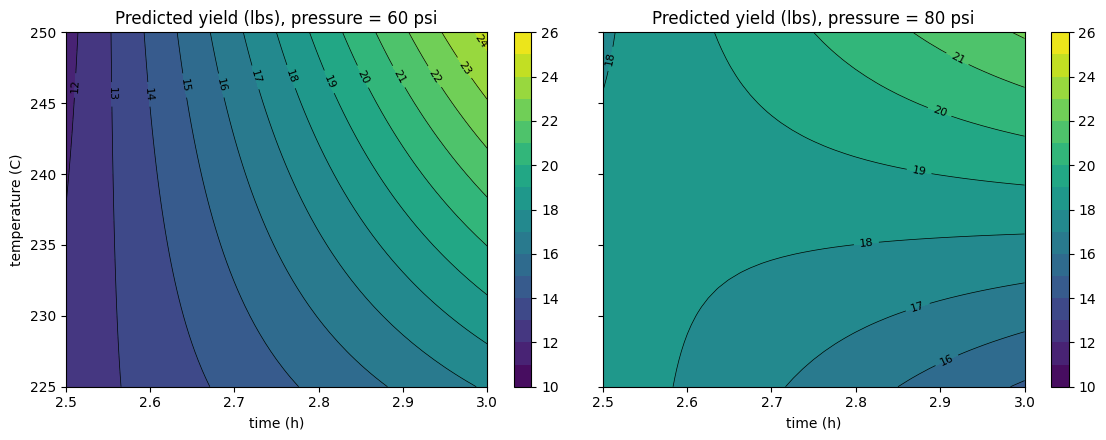

,5,7,2,3,4,6,0,1
A,1.000,1.000,-1.000,-1.000,1.000,1.000,-1.000,-1.000
C,-1.000,1.000,1.000,1.000,-1.000,1.000,-1.000,-1.000
D,1.000,1.000,-1.000,1.000,-1.000,-1.000,-1.000,1.000
predicted,24.375,22.125,18.625,17.875,17.125,14.875,12.375,11.625


effect of temperature (D) at 2.5 h: -0.75   at 3 h: 7.25
effect of pressure (C) at 2.5 h:    6.25   at 3 h: -2.25
effect of time (A) at 60 psi, 250 C: 12.75   at 80 psi, 225 C: -3.75
se of a predicted corner mean: 0.78 lbs


In [31]:
# 6.29: contour plots of the predicted yield over time x temperature at both pressures, corner predictions
g = np.linspace(-1, 1, 41)
X1, X4 = np.meshgrid(g, g)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5), sharey=True)
levels = np.arange(10, 27, 1)
for ax, x3 in zip(axes, [-1, 1]):
    Z = m628.predict(pd.DataFrame({"A": X1.ravel(), "C": x3, "D": X4.ravel()})).to_numpy().reshape(X1.shape)
    cs = ax.contourf(2.75 + 0.25 * X1, 237.5 + 12.5 * X4, Z, levels=levels, cmap="viridis")
    ax.clabel(ax.contour(2.75 + 0.25 * X1, 237.5 + 12.5 * X4, Z, levels=levels, colors="k", linewidths=0.5),
              fontsize=8, fmt="%.0f")
    ax.set(xlabel="time (h)", title=f"Predicted yield (lbs), pressure = {70 + 10 * x3:.0f} psi")
    fig.colorbar(cs, ax=ax)
axes[0].set_ylabel("temperature (C)")
plt.tight_layout(); plt.show()

corners = pd.DataFrame(list(itertools.product([-1, 1], repeat=3)), columns=["A", "C", "D"])
corners["predicted"] = m628.predict(corners)
display(corners.sort_values("predicted", ascending=False).round(3).T)
print("effect of temperature (D) at 2.5 h:", round(2 * (b["D"] - b["A:D"]), 2), "  at 3 h:", round(2 * (b["D"] + b["A:D"]), 2))
print("effect of pressure (C) at 2.5 h:   ", round(2 * (b["C"] - b["A:C"]), 2), "  at 3 h:", round(2 * (b["C"] + b["A:C"]), 2))
print("effect of time (A) at 60 psi, 250 C:", round(2 * (b["A"] - b["A:C"] + b["A:D"]), 2),
      "  at 80 psi, 225 C:", round(2 * (b["A"] + b["A:C"] - b["A:D"]), 2))
print(f"se of a predicted corner mean: {np.sqrt(m628.mse_resid * 6 / 16):.2f} lbs")

**Practical value.** At 60 psi the contours fan out: at 2.5 h the temperature does nothing (12.4 vs 11.6 lbs), at 3 h it adds
7 lbs (17.1 to 24.4); the time pays off far more at 250 C ($+12.8$) than at 225 C ($+4.8$). At 80 psi the surface is a saddle
around 18 lbs: a longer time lowers the yield at 225 C (18.6 to 14.9) and raises it at 250 C (17.9 to 22.1). The plot
therefore shows where to operate now (3 h, 250 C, 60 psi, 24.4 lbs), where to move next (longer time and higher temperature
at low pressure) and that time and temperature must be changed together.

Limitations: no quadratic terms and no center points, so curvature cannot be checked and the surface is valid only inside the
region (2.5 to 3 h, 225 to 250 C, 60 to 80 psi). The corner predictions have $se \approx 0.8$ lbs, so one contour step (1 lb)
is within the noise.

**Conclusions (Problem 6.29)**

* The contours at 60 and 80 psi show a twisted plane: the time pays off mainly at high temperature and low pressure; at 80 psi
  and 225 C a longer time even lowers the yield.
* Recommended: 3 h, 250 C, 60 psi (24.4 lbs); next experiment towards longer times and higher temperatures at low pressure,
  with center points.

### Problems 6.31 and 6.32: a polymer (molecular weight and viscosity)

An experiment was conducted on a chemical process that produces a polymer. The four factors studied were temperature
($A$: 100 and 120 $^\circ$C), catalyst concentration ($B$: 4 and 8 %), time ($C$: 20 and 30 min) and pressure ($D$: 60 and
75 psi). Two responses, molecular weight and viscosity, were observed. The file `Problem_6_31.txt` contains the 16 runs of the
$2^4$ design in standard order followed by 4 center points.

**Use only the first 16 runs** (the factorial part). The center points and the test for curvature (part (b) of 6.31)
will come in Lecture 7.

In [32]:
p631 = pd.read_csv(URL + "Problem_6_31.txt", sep=";")
p631 = p631.iloc[:16].copy()          # the 2^4 runs only
p631

,Temperature,Concentration,Time,Pressure,Weight,Viscosity
0,100,4,20,60.0,2400,1400
1,120,4,20,60.0,2410,1500
2,100,8,20,60.0,2315,1520
3,120,8,20,60.0,2510,1630
4,100,4,30,60.0,2615,1380
5,120,4,30,60.0,2625,1525
6,100,8,30,60.0,2400,1500
7,120,8,30,60.0,2750,1620
8,100,4,20,75.0,2400,1400
9,120,4,20,75.0,2390,1525


**Problem 6.31**

(a) Consider only the molecular weight response. Plot the effect estimates on a normal probability scale. What effects
appear important?

(b) Use an analysis of variance to confirm the results from part (a).

(c) Write down a regression model to predict molecular weight as a function of the important variables.

(d) Analyze the residuals and comment on model adequacy.

(e) Repeat parts (a)-(d) using the viscosity response.

**Solution:**

**(a) Molecular weight.** Coding: $A$ temperature ($x_1 = (T - 110)/10$), $B$ catalyst ($x_2 = (c - 6)/2$), $C$ time
($x_3 = (t - 25)/5$), $D$ pressure ($x_4 = (p - 67.5)/7.5$); 16 factorial runs. Effects, normal plots, Lenth's method.

term,A,B,A:B,C,A:C,B:C,A:B:C,D,A:D,B:D,A:B:D,C:D,A:C:D,B:C:D,A:B:C:D
effect,123.75,-11.25,120.0,201.25,20.0,-22.50,16.25,6.25,-17.50,7.50,-11.25,12.50,-18.75,3.75,-22.50
SS,61256.25,506.25,57600.0,162006.25,1600.0,2025.00,1056.25,156.25,1225.00,225.00,506.25,625.00,1406.25,56.25,2025.00
coef,61.88,-5.62,60.0,100.62,10.0,-11.25,8.12,3.12,-8.75,3.75,-5.62,6.25,-9.38,1.88,-11.25


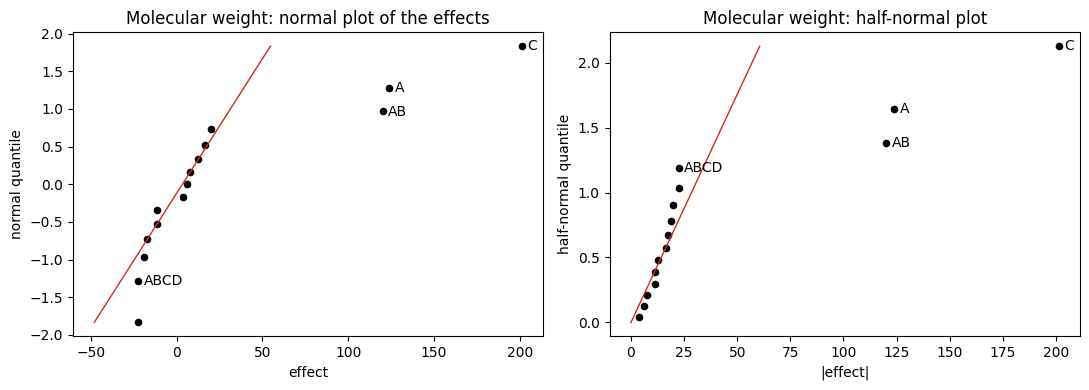

{'s0': 26.25, 'PSE': 21.56, 'ME': 55.43, 'SME': 112.53}
|effect| > ME : ['A', 'AB', 'C']    |effect| > SME: ['A', 'AB', 'C']
|effect| / PSE: {'C': 9.33, 'A': 5.74, 'AB': 5.57, 'BC': 1.04, 'ABCD': 1.04, 'AC': 0.93}


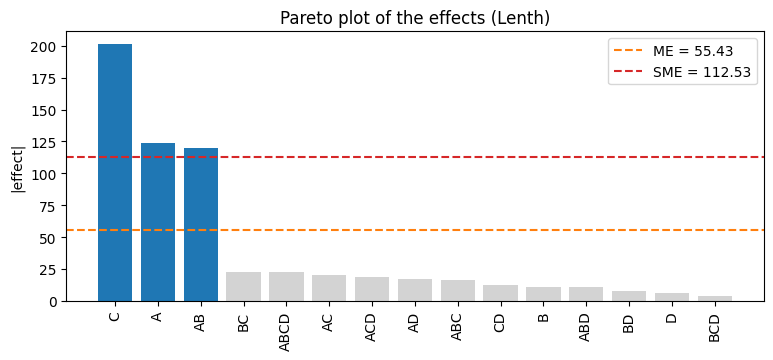

In [33]:
# 6.31a: coded factors, effects of the molecular weight, normal / half-normal plots, Lenth's method
p631["A"] = np.where(p631["Temperature"] == 120, 1, -1)
p631["B"] = np.where(p631["Concentration"] == 8, 1, -1)
p631["C"] = np.where(p631["Time"] == 30, 1, -1)
p631["D"] = np.where(p631["Pressure"] == 75, 1, -1)
t_mw = effects_2k(p631, "Weight", F4)
e_mw = t_mw["effect"].rename(lambda t: t.replace(":", ""))
display(t_mw[["effect", "SS", "coef"]].round(2).T)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(e_mw, n_label=4, ax=axes[0], title="Molecular weight: normal plot of the effects")
effect_plot(e_mw, half=True, n_label=4, ax=axes[1], title="Molecular weight: half-normal plot")
plt.tight_layout(); plt.show()
L_mw = lenth(e_mw)
print({k: round(v, 2) for k, v in L_mw.items()})
print("|effect| > ME :", list(e_mw[e_mw.abs() > L_mw["ME"]].index), "   |effect| > SME:", list(e_mw[e_mw.abs() > L_mw["SME"]].index))
print("|effect| / PSE:", (e_mw.abs() / L_mw["PSE"]).sort_values(ascending=False).round(2).head(6).to_dict())
pareto_plot(e_mw); plt.show()

Three effects are far off the line: $C = 201.25$ (time), $A = 123.75$ (temperature) and $AB = 120.0$. The other twelve are at
most 22.5 in absolute value. Lenth: $PSE = 21.6$, $ME = 55.4$, $SME = 112.5$; $C$, $A$, $AB$ exceed even $SME$, the next
effect is $1.04\,PSE$. $B = -11.25$ is negligible alone but stays for hierarchy; pressure $D$ has no effect.

**(b) ANOVA.** `Weight ~ A + B + C + A:B`, error = the eleven negligible effects (11 df); $H_0$: effect $= 0$, $F_0$ with
$(1, 11)$ df, $\alpha = 0.05$. Lack of fit is checked against the model with all two-factor interactions (error = 3fi + 4fi,
5 df).

In [34]:
# 6.31b: ANOVA of the molecular weight model with pooled error; lack-of-fit check against the 2fi model
m_mw = smf.ols("Weight ~ A + B + C + A:B", data=p631).fit()
display(anova_lm(m_mw).round(4))
print(f"MS_E = {m_mw.mse_resid:.1f} ({m_mw.df_resid:.0f} df), s = {np.sqrt(m_mw.mse_resid):.1f}, "
      f"R2 = {m_mw.rsquared:.4f}, adj. R2 = {m_mw.rsquared_adj:.4f}")
m_mw_2fi = smf.ols("Weight ~ (A + B + C + D)**2", data=p631).fit()
print("\nthe dropped D and six two-factor interactions tested against the 3fi + 4fi error (5 df):")
display(anova_lm(m_mw, m_mw_2fi).round(4))

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,61256.25,61256.2500,61.7828,0.0000
B,1.0,506.25,506.2500,0.5106,0.4898
C,1.0,162006.25,162006.2500,163.3989,0.0000
A:B,1.0,57600.00,57600.0000,58.0951,0.0000
Residual,11.0,10906.25,991.4773,NaN,NaN


MS_E = 991.5 (11 df), s = 31.5, R2 = 0.9627, adj. R2 = 0.9491

the dropped D and six two-factor interactions tested against the 3fi + 4fi error (5 df):


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,11.0,10906.25,0.0,NaN,NaN,NaN
1,5.0,5050.00,6.0,5856.25,0.9664,0.5258


| Term | $SS$ | $F_0$ (1, 11 df) | $p$-value | Decision |
|---|---|---|---|---|
| $A$ | 61 256 | 61.78 | $< 0.0001$ | reject $H_0$ |
| $B$ | 506 | 0.51 | 0.49 | keep for hierarchy |
| $C$ | 162 006 | 163.4 | $< 0.0001$ | reject $H_0$ |
| $AB$ | 57 600 | 58.10 | $< 0.0001$ | reject $H_0$ |

The seven dropped terms add nothing ($F_0 = 0.97$, $p = 0.53$), so the pooled error is justified: $MS_E = 991$,
$\hat\sigma = 31.5$, $R^2 = 0.963$.

**(c) Regression model** (coded units, coefficients = effects / 2).

In [35]:
# 6.31c: regression model for the molecular weight (coded units) and the simple effects behind the AB interaction
print(m_mw.summary().tables[1])
bw = m_mw.params
print(f"\nMW_hat = {bw['Intercept']:.2f} + {bw['A']:.3f} x1 {bw['B']:+.3f} x2 + {bw['C']:.3f} x3 + {bw['A:B']:.3f} x1 x2")
print("effect of temperature (A) at 4 % catalyst:", round(2 * (bw["A"] - bw["A:B"]), 1), "  at 8 %:", round(2 * (bw["A"] + bw["A:B"]), 1))
print("effect of catalyst (B) at 100 C:          ", round(2 * (bw["B"] - bw["A:B"]), 1), "  at 120 C:", round(2 * (bw["B"] + bw["A:B"]), 1))
m_mw_nh = smf.ols("Weight ~ A + C + A:B", data=p631).fit()
print(f"non-hierarchical model without B: MS_E = {m_mw_nh.mse_resid:.1f} ({m_mw_nh.df_resid:.0f} df), R2 = {m_mw_nh.rsquared:.4f}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   2506.2500      7.872    318.378      0.000    2488.924    2523.576
A             61.8750      7.872      7.860      0.000      44.549      79.201
B             -5.6250      7.872     -0.715      0.490     -22.951      11.701
C            100.6250      7.872     12.783      0.000      83.299     117.951
A:B           60.0000      7.872      7.622      0.000      42.674      77.326

MW_hat = 2506.25 + 61.875 x1 -5.625 x2 + 100.625 x3 + 60.000 x1 x2
effect of temperature (A) at 4 % catalyst: 3.7   at 8 %: 243.8
effect of catalyst (B) at 100 C:           -131.3   at 120 C: 108.8
non-hierarchical model without B: MS_E = 951.0 (12 df), R2 = 0.9610


$$\widehat{MW} = 2506.25 + 61.88\,x_1 - 5.63\,x_2 + 100.63\,x_3 + 60.00\,x_1 x_2.$$
Time adds about 201 regardless of the other factors. Temperature and catalyst act together: 100 to 120 C adds 244 at 8 %
catalyst but only 4 at 4 %; 4 to 8 % catalyst lowers the molecular weight by 131 at 100 C and raises it by 109 at 120 C.
Dropping $B$ changes little ($MS_E = 951$); the hierarchical form is kept.

**(d) Residuals of the molecular weight model.**

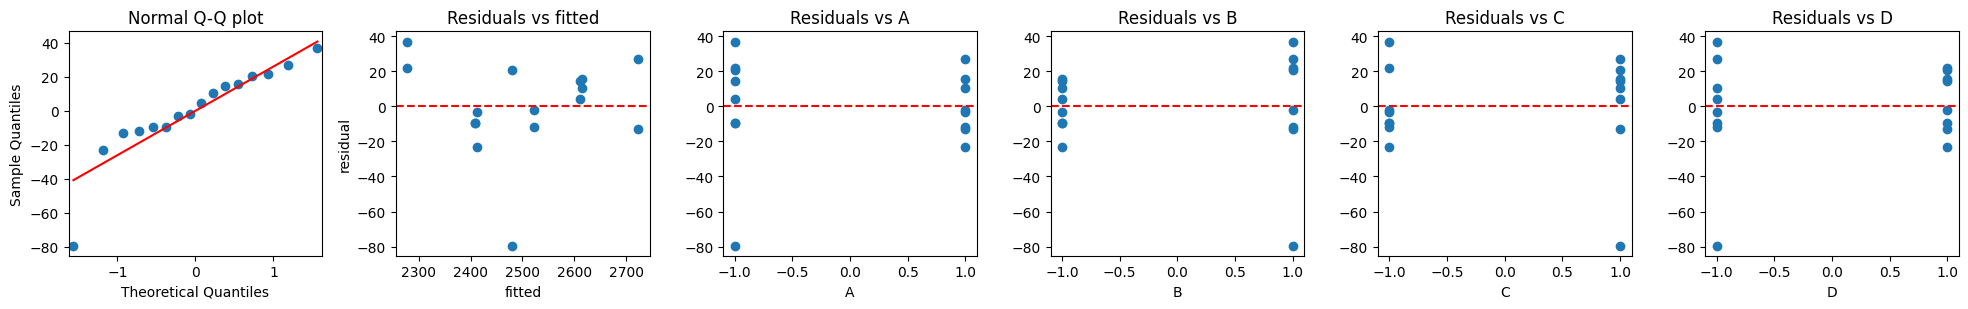

Shapiro-Wilk on residuals: ShapiroResult(statistic=0.8680678943976095, pvalue=0.025409128758614168)
largest |residual| = 79.4 at run 7 (standard order): {'Temperature': 100.0, 'Concentration': 8.0, 'Time': 30.0, 'Pressure': 60.0, 'Weight': 2400.0}  fitted 2479.4
all other residuals within +/- 36.9


In [36]:
# 6.31d: residual analysis, molecular weight
residual_plots(m_mw, p631, F4)
r = m_mw.resid
i_max = r.abs().idxmax()
print(f"largest |residual| = {r.abs().max():.1f} at run {i_max + 1} (standard order):",
      p631.loc[i_max, ["Temperature", "Concentration", "Time", "Pressure", "Weight"]].to_dict(),
      f" fitted {m_mw.fittedvalues[i_max]:.1f}")
print(f"all other residuals within +/- {r.drop(i_max).abs().max():.1f}")

All residuals are within $\pm 37$ except run 7 (100 C, 8 %, 30 min, 60 psi: observed 2400, fitted 2479, residual
$-79 \approx 2.5\,\hat\sigma$). It alone makes Shapiro-Wilk reject ($W = 0.868$, $p = 0.025$). Otherwise no funnel and no
pattern against any factor, including $D$. The model is adequate; run 7 should be re-checked in the records.

**(e) Viscosity.** The same steps for the second response.

term,A,B,A:B,C,A:C,B:C,A:B:C,D,A:D,B:D,A:B:D,C:D,A:C:D,B:C:D,A:B:C:D
effect,96.25,91.25,-13.75,7.50,12.50,10.0,15.0,-17.50,-22.50,-25.0,-10.0,13.75,-1.25,18.75,23.75
SS,37056.25,33306.25,756.25,225.00,625.00,400.0,900.0,1225.00,2025.00,2500.0,400.0,756.25,6.25,1406.25,2256.25
coef,48.12,45.62,-6.88,3.75,6.25,5.0,7.5,-8.75,-11.25,-12.5,-5.0,6.88,-0.62,9.38,11.88


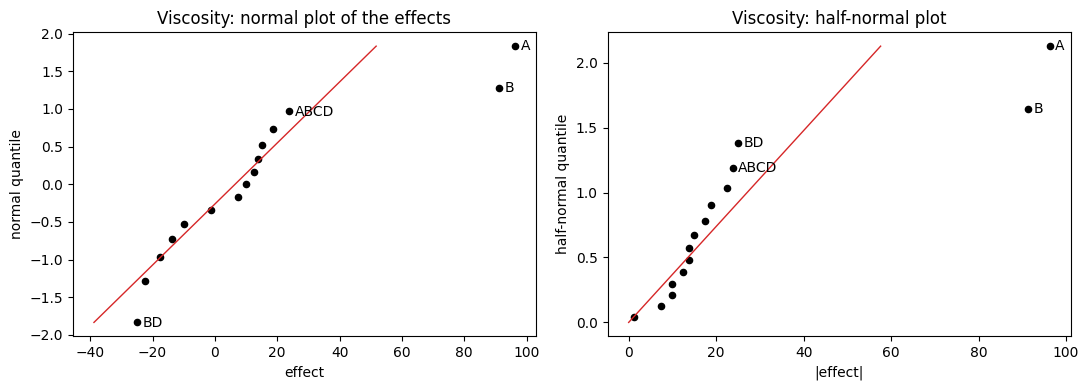

{'s0': 22.5, 'PSE': 20.62, 'ME': 53.02, 'SME': 107.63}
|effect| > ME : ['A', 'B']    |effect| > SME: []
|effect| / PSE: {'A': 4.67, 'B': 4.42, 'BD': 1.21, 'ABCD': 1.15, 'AD': 1.09, 'BCD': 0.91}


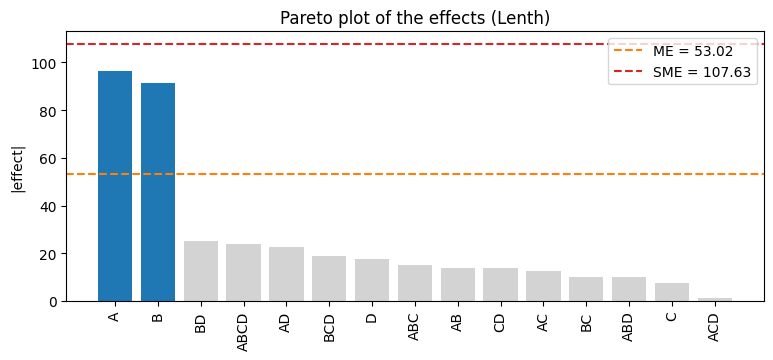

In [37]:
# 6.31e: viscosity, effects and plots
t_v = effects_2k(p631, "Viscosity", F4)
e_v = t_v["effect"].rename(lambda t: t.replace(":", ""))
display(t_v[["effect", "SS", "coef"]].round(2).T)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(e_v, n_label=4, ax=axes[0], title="Viscosity: normal plot of the effects")
effect_plot(e_v, half=True, n_label=4, ax=axes[1], title="Viscosity: half-normal plot")
plt.tight_layout(); plt.show()
L_v = lenth(e_v)
print({k: round(v, 2) for k, v in L_v.items()})
print("|effect| > ME :", list(e_v[e_v.abs() > L_v["ME"]].index), "   |effect| > SME:", list(e_v[e_v.abs() > L_v["SME"]].index))
print("|effect| / PSE:", (e_v.abs() / L_v["PSE"]).sort_values(ascending=False).round(2).head(6).to_dict())
pareto_plot(e_v); plt.show()

Two effects leave the line: $A = 96.25$ and $B = 91.25$; the other thirteen are at most 25 in absolute value. Lenth:
$PSE = 20.6$, $ME = 53.0$, $SME = 107.6$; $A$ and $B$ exceed $ME$ (4.7 and 4.4 $PSE$), nothing else exceeds $1.3\,PSE$.
Model `Viscosity ~ A + B`, pooled error 13 df, $F_0$ with $(1, 13)$ df.

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,37056.25,37056.2500,35.7334,0.0000
B,1.0,33306.25,33306.2500,32.1173,0.0001
Residual,13.0,13481.25,1037.0192,NaN,NaN


MS_E = 1037.0 (13 df), s = 32.2, R2 = 0.8392, adj. R2 = 0.8145
AB added to the model: {'F': 0.713, 'PR(>F)': 0.415}
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1500.6250      8.051    186.397      0.000    1483.233    1518.017
A             48.1250      8.051      5.978      0.000      30.733      65.517
B             45.6250      8.051      5.667      0.000      28.233      63.017

V_hat = 1500.63 + 48.125 x1 + 45.625 x2


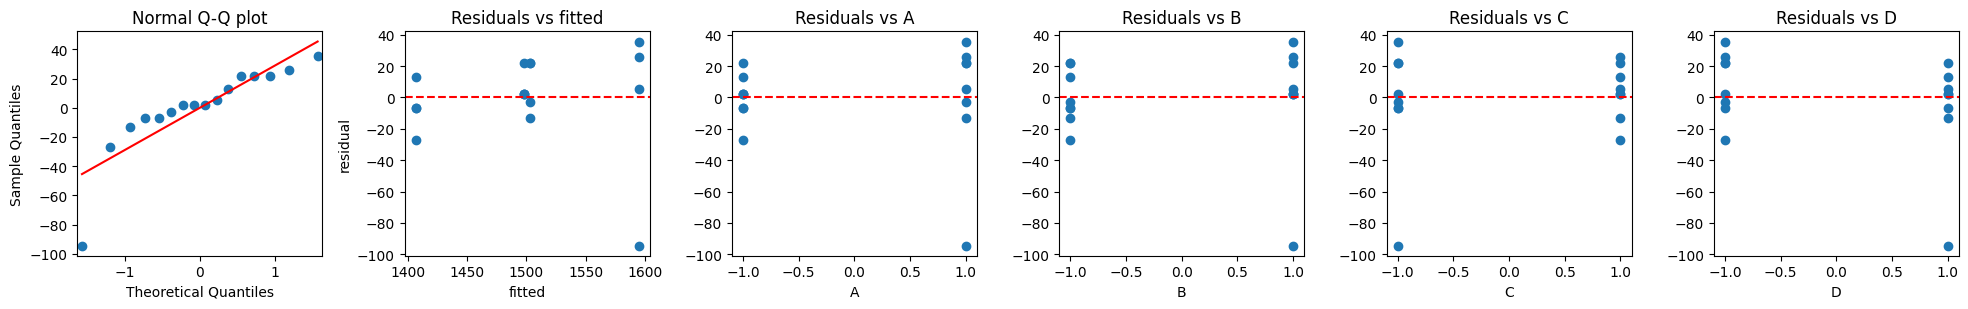

Shapiro-Wilk on residuals: ShapiroResult(statistic=0.7933729462974481, pvalue=0.002226960359649832)
largest |residual| = 94.4 at run 12 (standard order): {'Temperature': 120.0, 'Concentration': 8.0, 'Time': 20.0, 'Pressure': 75.0, 'Viscosity': 1500.0}  fitted 1594.4
all other residuals within +/- 35.6
the four runs at 120 C and 8 %: [1630, 1620, 1500, 1600]


In [38]:
# 6.31e (cont.): viscosity ANOVA, regression model (coded units) and residuals
m_v = smf.ols("Viscosity ~ A + B", data=p631).fit()
display(anova_lm(m_v).round(4))
print(f"MS_E = {m_v.mse_resid:.1f} ({m_v.df_resid:.0f} df), s = {np.sqrt(m_v.mse_resid):.1f}, "
      f"R2 = {m_v.rsquared:.4f}, adj. R2 = {m_v.rsquared_adj:.4f}")
print("AB added to the model:", anova_lm(smf.ols("Viscosity ~ A + B + A:B", data=p631).fit()).loc["A:B", ["F", "PR(>F)"]].round(3).to_dict())
print(m_v.summary().tables[1])
bv = m_v.params
print(f"\nV_hat = {bv['Intercept']:.2f} + {bv['A']:.3f} x1 + {bv['B']:.3f} x2")
residual_plots(m_v, p631, F4)
r = m_v.resid
i_max = r.abs().idxmax()
print(f"largest |residual| = {r.abs().max():.1f} at run {i_max + 1} (standard order):",
      p631.loc[i_max, ["Temperature", "Concentration", "Time", "Pressure", "Viscosity"]].to_dict(),
      f" fitted {m_v.fittedvalues[i_max]:.1f}")
print(f"all other residuals within +/- {r.drop(i_max).abs().max():.1f}")
print("the four runs at 120 C and 8 %:", p631.loc[(p631.A == 1) & (p631.B == 1), "Viscosity"].tolist())

| Term | $SS$ | $F_0$ (1, 13 df) | $p$-value | Decision |
|---|---|---|---|---|
| $A$ | 37 056 | 35.73 | $< 0.0001$ | reject $H_0$ |
| $B$ | 33 306 | 32.12 | 0.0001 | reject $H_0$ |

$$\hat V = 1500.63 + 48.13\,x_1 + 45.63\,x_2, \qquad R^2 = 0.839,\ \hat\sigma = 32.2.$$

No interaction is needed ($F_0 = 0.71$, $p = 0.41$): 100 to 120 C adds about 96, 4 to 8 % catalyst about 91, additively.
Run 12 (120 C, 8 %, 20 min, 75 psi: viscosity 1500, fitted 1594, residual $-94 \approx 3\,\hat\sigma$) stands out; the other
three runs at 120 C and 8 % gave 1600 to 1630, so 1500 may be a recording error. It causes the rejected normality test
($W = 0.793$, $p = 0.002$); the other residuals are within $\pm 36$ without pattern.

**Conclusions (Problem 6.31)**

* Molecular weight: $C$ ($+201$), $A$ ($+124$), $AB$ ($+120$) active, $B$ kept for hierarchy;
  $\widehat{MW} = 2506 + 61.9\,x_1 - 5.6\,x_2 + 100.6\,x_3 + 60.0\,x_1 x_2$, $R^2 = 0.96$.
* Viscosity: only $A$ ($+96$) and $B$ ($+91$); $\hat V = 1501 + 48.1\,x_1 + 45.6\,x_2$, $R^2 = 0.84$. Pressure affects
  neither response.
* One suspicious run per response (7 and 12); otherwise the residuals are acceptable, no transformation needed.

**Problem 6.32.** Use the regression models for molecular weight and viscosity to answer the following questions.

(a) Construct a response surface contour plot for molecular weight. In what direction would you adjust the process variables
to increase molecular weight?

(b) Construct a response surface contour plot for viscosity. In what direction would you adjust the process variables to
decrease viscosity?

(c) What operating conditions would you recommend if it was necessary to produce a product with molecular weight between
2400 and 2500 and the lowest possible viscosity?

**Solution:**

**(a) Molecular weight contours** over temperature $\times$ catalyst at 20 and 30 min (natural units); pressure is irrelevant.

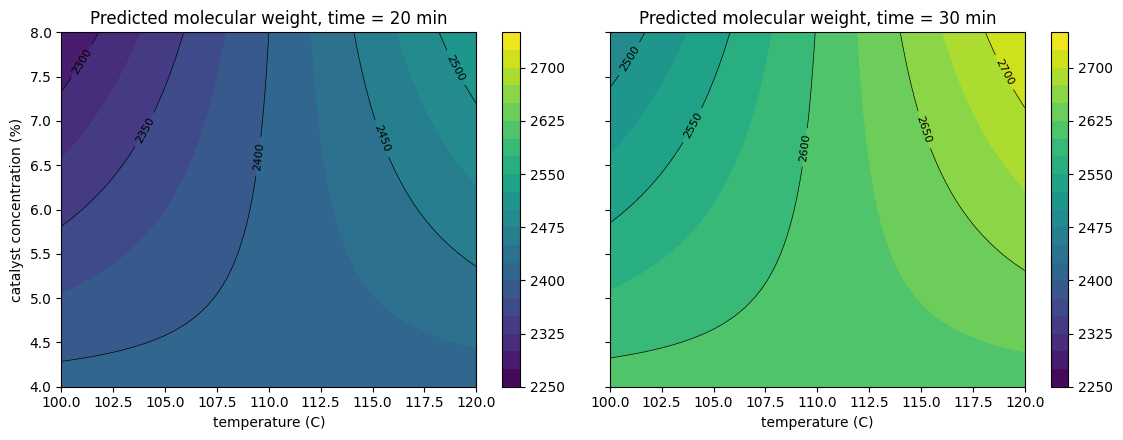

,7,5,1,6,3,4,0,2
A,1.0,1.0,-1.0,1.0,-1.0,1.0,-1.0,-1.0
B,1.0,-1.0,-1.0,1.0,1.0,-1.0,-1.0,1.0
C,1.0,1.0,1.0,-1.0,1.0,-1.0,-1.0,-1.0
MW,2723.1,2614.4,2610.6,2521.9,2479.4,2413.1,2409.4,2278.1
viscosity,1594.4,1503.1,1406.9,1594.4,1498.1,1503.1,1406.9,1498.1


In [39]:
# 6.32a: molecular weight over temperature x catalyst at 20 and 30 min; predictions at the corners
g = np.linspace(-1, 1, 41)
X1, X2 = np.meshgrid(g, g)
temp, conc = 110 + 10 * X1, 6 + 2 * X2
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5), sharey=True)
levels = np.arange(2250, 2751, 25)
for ax, x3 in zip(axes, [-1, 1]):
    Z = m_mw.predict(pd.DataFrame({"A": X1.ravel(), "B": X2.ravel(), "C": x3})).to_numpy().reshape(X1.shape)
    cs = ax.contourf(temp, conc, Z, levels=levels, cmap="viridis")
    ax.clabel(ax.contour(temp, conc, Z, levels=levels[::2], colors="k", linewidths=0.5), fontsize=8, fmt="%.0f")
    ax.set(xlabel="temperature (C)", title=f"Predicted molecular weight, time = {25 + 5 * x3:.0f} min")
    fig.colorbar(cs, ax=ax)
axes[0].set_ylabel("catalyst concentration (%)")
plt.tight_layout(); plt.show()
corners = pd.DataFrame(list(itertools.product([-1, 1], repeat=3)), columns=["A", "B", "C"])
corners["MW"] = m_mw.predict(corners)
corners["viscosity"] = m_v.predict(corners)
display(corners.sort_values("MW", ascending=False).round(1).T)

To **increase the molecular weight**: lengthen the time (about $+200$ between the panels) and raise temperature and catalyst
together (upper right corner, 2723 at 120 C, 8 %, 30 min). The interaction twists the surface: at 4 % catalyst the temperature
does nothing and at 100 C more catalyst lowers the molecular weight, so the two must move jointly.

**(b) Viscosity contours.** Only the main effects of temperature and catalyst, so parallel straight lines, the same at every
time and pressure.

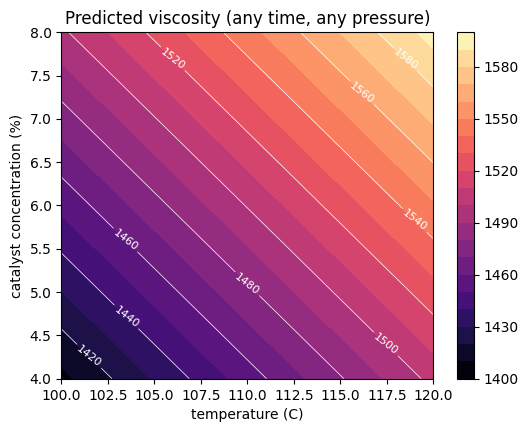

In [40]:
# 6.32b: viscosity over temperature x catalyst (independent of time and pressure)
fig, ax = plt.subplots(figsize=(6, 4.5))
Zv = m_v.predict(pd.DataFrame({"A": X1.ravel(), "B": X2.ravel()})).to_numpy().reshape(X1.shape)
levels_v = np.arange(1400, 1601, 10)
cs = ax.contourf(temp, conc, Zv, levels=levels_v, cmap="magma")
ax.clabel(ax.contour(temp, conc, Zv, levels=levels_v[::2], colors="w", linewidths=0.5), fontsize=8, fmt="%.0f")
ax.set(xlabel="temperature (C)", ylabel="catalyst concentration (%)", title="Predicted viscosity (any time, any pressure)")
fig.colorbar(cs, ax=ax)
plt.show()

To **decrease the viscosity** move to the lower left: lower temperature and lower catalyst, with about equal weight
(coefficients 48 and 46). Minimum in the region: 100 C, 4 %, about 1407; time and pressure are free.

**(c) $2400 \le MW \le 2500$ with the lowest viscosity.** The viscosity is smallest at $x_1 = x_2 = -1$ (100 C, 4 %), where
$\widehat{MW} = 2510.0 + 100.6\,x_3$: the window holds for $-1.09 \le x_3 \le -0.10$, i.e. 20 to about 24.5 min. Checked on
a grid and drawn as the hatched band on the viscosity surface.

27470 of 68921 grid points give 2400 <= MW <= 2500; the lowest viscosities among them:


,A,B,C,MW,viscosity
0,-1.0,-1.0,-1.00,2409.38,1406.88
1,-1.0,-1.0,-0.95,2414.41,1406.88
2,-1.0,-1.0,-0.90,2419.44,1406.88
3,-1.0,-1.0,-0.85,2424.47,1406.88
4,-1.0,-1.0,-0.80,2429.50,1406.88


-> temperature 100 C, catalyst 4 %, time 20.0 min: MW 2409, viscosity 1407
at 100 C and 4 %: MW = 2510.0 + 100.63 x3, feasible x3 in [-1.09, -0.10] -> time from 20 to 24.5 min


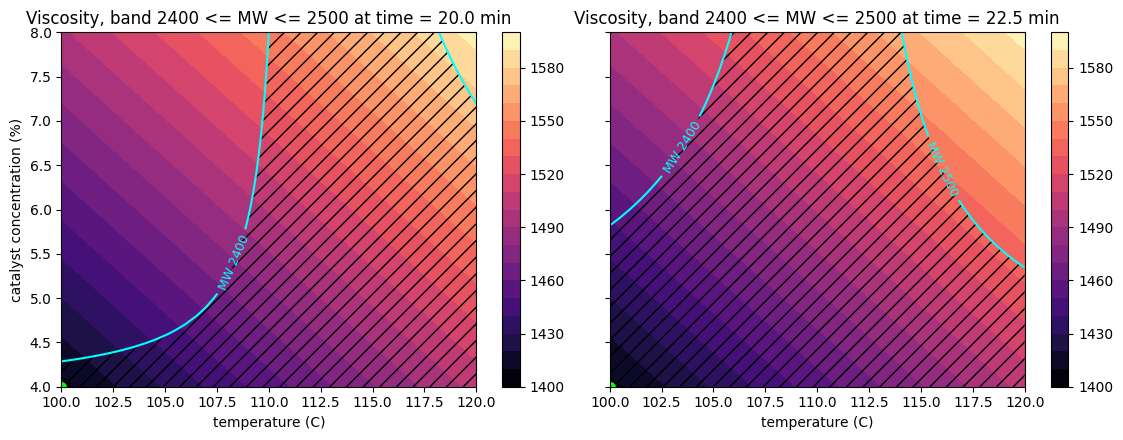

In [41]:
# 6.32c: feasible region 2400 <= MW <= 2500 and the lowest viscosity inside it
grid = pd.DataFrame(list(itertools.product(np.linspace(-1, 1, 41), repeat=3)), columns=["A", "B", "C"])
grid["MW"] = m_mw.predict(grid)
grid["viscosity"] = m_v.predict(grid)
feas = grid[grid["MW"].between(2400, 2500)]
print(f"{len(feas)} of {len(grid)} grid points give 2400 <= MW <= 2500; the lowest viscosities among them:")
display(feas.sort_values(["viscosity", "MW"]).head(5).round(2))
best = feas.loc[feas["viscosity"].idxmin()]
print(f"-> temperature {110 + 10 * best['A']:.0f} C, catalyst {6 + 2 * best['B']:.0f} %, time {25 + 5 * best['C']:.1f} min: "
      f"MW {best['MW']:.0f}, viscosity {best['viscosity']:.0f}")
base = bw["Intercept"] - bw["A"] - bw["B"] + bw["A:B"]
lo, hi = (2400 - base) / bw["C"], (2500 - base) / bw["C"]
print(f"at 100 C and 4 %: MW = {base:.1f} + {bw['C']:.2f} x3, feasible x3 in [{lo:.2f}, {hi:.2f}] "
      f"-> time from 20 to {25 + 5 * hi:.1f} min")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5), sharey=True)
for ax, x3 in zip(axes, [-1, -0.5]):
    Zm = m_mw.predict(pd.DataFrame({"A": X1.ravel(), "B": X2.ravel(), "C": x3})).to_numpy().reshape(X1.shape)
    cs = ax.contourf(temp, conc, Zv, levels=levels_v, cmap="magma")
    ax.contourf(temp, conc, Zm, levels=[2400, 2500], colors="none", hatches=["//"])
    ax.clabel(ax.contour(temp, conc, Zm, levels=[2400, 2500], colors="cyan", linewidths=1.5), fontsize=9, fmt="MW %.0f")
    ax.plot(100, 4, "o", color="lime", ms=9, mec="k")
    ax.set(xlabel="temperature (C)", title=f"Viscosity, band 2400 <= MW <= 2500 at time = {25 + 5 * x3:.1f} min")
    fig.colorbar(cs, ax=ax)
axes[0].set_ylabel("catalyst concentration (%)")
plt.tight_layout(); plt.show()

**Recommendation:** 100 C, 4 % catalyst, 20 to 24 min (e.g. 22 min, $\widehat{MW} \approx 2450$), any pressure between 60
and 75 psi. Predicted viscosity about 1407, the lowest the model allows; 20 min gives $\widehat{MW} = 2409$, close to the lower
limit, so a slightly longer time is safer ($\hat\sigma_{MW} = 31$). Confirm with a few runs at these conditions.

**Conclusions (Problem 6.32)**

* Molecular weight rises with the time and with temperature and catalyst raised jointly; viscosity falls towards low
  temperature and low catalyst, independently of time and pressure.
* For $2400 \le MW \le 2500$ with minimal viscosity: 100 C, 4 %, 20 to 24 min, any pressure; viscosity about 1407.

### Problem 6.36: resistivity of a silicon wafer

Resistivity on a silicon wafer is influenced by several factors. The results of a single replicate of a $2^4$ factorial
experiment performed during a critical processing step are (standard order):

In [42]:
p636 = pd.DataFrame([r[::-1] for r in itertools.product([-1, 1], repeat=4)], columns=list("ABCD"))
p636["resistivity"] = [1.92, 11.28, 1.09, 5.75, 2.13, 9.53, 1.03, 5.35,
                       1.60, 11.73, 1.16, 4.68, 2.16, 9.11, 1.07, 5.30]
p636

,A,B,C,D,resistivity
0,-1,-1,-1,-1,1.92
1,1,-1,-1,-1,11.28
2,-1,1,-1,-1,1.09
3,1,1,-1,-1,5.75
4,-1,-1,1,-1,2.13
5,1,-1,1,-1,9.53
6,-1,1,1,-1,1.03
7,1,1,1,-1,5.35
8,-1,-1,-1,1,1.60
9,1,-1,-1,1,11.73


**Problem 6.36**

(a) Estimate the factor effects. Plot the effect estimates on a normal probability plot and select a tentative model.

(b) Fit the model identified in part (a) and analyze the residuals. Is there any indication of model inadequacy?

(c) Repeat the analysis from parts (a) and (b) using $\ln(y)$ as the response variable. Is there an indication that the
transformation has been useful?

(d) Fit a model in terms of the coded variables that can be used to predict the resistivity.

**Solution:**

**(a) Effects and tentative model.** Single replicate of a $2^4$ in standard order: effects, normal and half-normal plots,
Lenth's method ($m = 15$).

term,A,B,A:B,C,A:C,B:C,A:B:C,D,A:D,B:D,A:B:D,C:D,A:C:D,B:C:D,A:B:C:D
effect,6.321,-3.004,-2.139,-0.441,-0.596,0.459,0.689,-0.159,-0.114,-0.094,-0.194,0.059,-0.021,0.189,0.284
SS,159.833,36.090,18.297,0.779,1.422,0.842,1.898,0.101,0.052,0.035,0.150,0.014,0.002,0.143,0.322
coef,3.161,-1.502,-1.069,-0.221,-0.298,0.229,0.344,-0.079,-0.057,-0.047,-0.097,0.029,-0.011,0.094,0.142


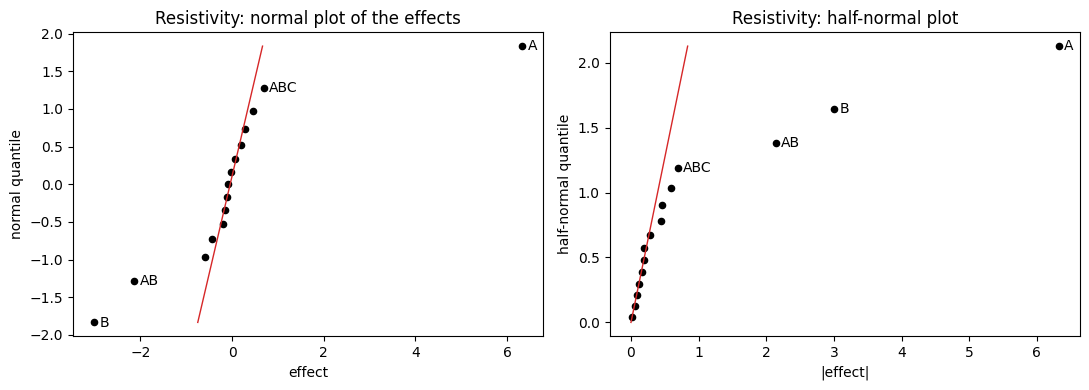

{'s0': 0.426, 'PSE': 0.287, 'ME': 0.737, 'SME': 1.497}
|effect| > ME : ['A', 'B', 'AB']    |effect| > SME: ['A', 'B', 'AB']
|effect| / PSE: {'A': 22.03, 'B': 10.47, 'AB': 7.46, 'ABC': 2.4, 'AC': 2.08, 'BC': 1.6}


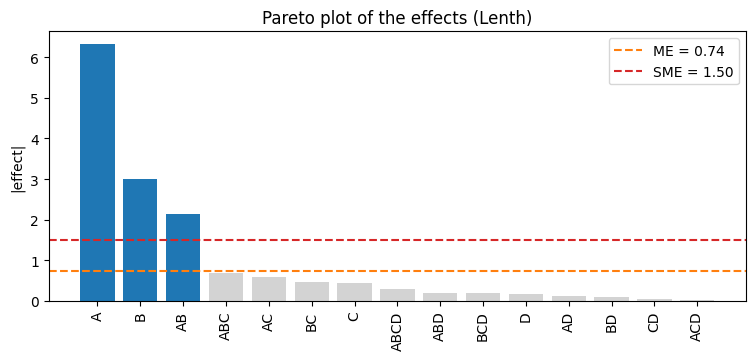

In [43]:
# 6.36a: effects of the resistivity, normal / half-normal plots, Lenth's method
t636 = effects_2k(p636, "resistivity", F4)
e636 = t636["effect"].rename(lambda t: t.replace(":", ""))
display(t636[["effect", "SS", "coef"]].round(3).T)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(e636, n_label=4, ax=axes[0], title="Resistivity: normal plot of the effects")
effect_plot(e636, half=True, n_label=4, ax=axes[1], title="Resistivity: half-normal plot")
plt.tight_layout(); plt.show()
L636 = lenth(e636)
print({k: round(v, 3) for k, v in L636.items()})
print("|effect| > ME :", list(e636[e636.abs() > L636["ME"]].index), "   |effect| > SME:", list(e636[e636.abs() > L636["SME"]].index))
print("|effect| / PSE:", (e636.abs() / L636["PSE"]).sort_values(ascending=False).round(2).head(6).to_dict())
pareto_plot(e636); plt.show()

$A = 6.32$ dominates, then $B = -3.00$ and $AB = -2.14$; the other twelve are at most 0.69. Lenth: $PSE = 0.287$,
$ME = 0.737$, $SME = 1.497$; $A$, $B$, $AB$ exceed $SME$, the next effect $ABC$ ($2.4\,PSE$) stays below $ME$. Tentative
model $A + B + AB$ (hierarchical); $C$, $D$ are inert, so the design projects into a $2^2$ with four replicates (12 df).

**(b) Fit and residuals.** `resistivity ~ A + B + A:B`, $H_0$: effect $= 0$, $F_0$ with $(1, 12)$ df. Residual plots,
Shapiro-Wilk test and the cell standard deviations.

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,159.8328,159.8328,333.0877,0.0
B,1.0,36.0901,36.0901,75.2108,0.0
A:B,1.0,18.2970,18.2970,38.1305,0.0
Residual,12.0,5.7582,0.4799,NaN,NaN


                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      4.6806      0.173     27.028      0.000       4.303       5.058
A              3.1606      0.173     18.251      0.000       2.783       3.538
B             -1.5019      0.173     -8.672      0.000      -1.879      -1.125
A:B           -1.0694      0.173     -6.175      0.000      -1.447      -0.692
MS_E = 0.4799 (12 df), R2 = 0.9738, adj. R2 = 0.9673


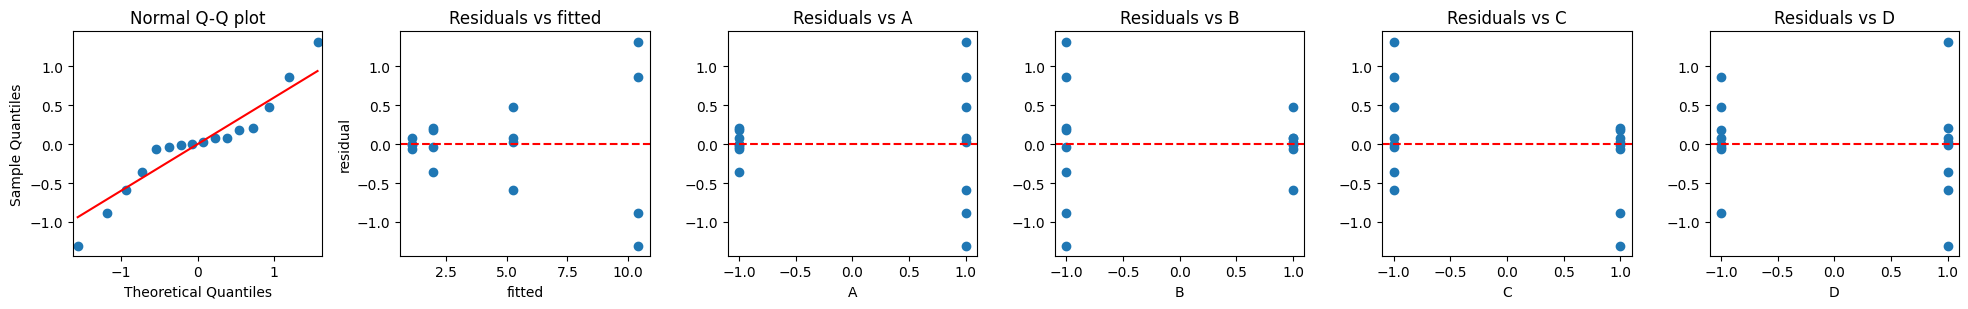

Shapiro-Wilk on residuals: ShapiroResult(statistic=0.9428466534821187, pvalue=0.3853569926239604)


mean    std  std / mean
A  B                            
-1 -1   1.953  0.258       0.132
    1   1.088  0.054       0.050
 1 -1  10.412  1.286       0.124
    1   5.270  0.442       0.084

ratio of cell means, A high / A low: at B = -1: 5.33  at B = +1: 4.85


In [44]:
# 6.36b: fit of the tentative model on the original scale and its residuals
m636 = smf.ols("resistivity ~ A + B + A:B", data=p636).fit()
display(anova_lm(m636).round(4))
print(m636.summary().tables[1])
print(f"MS_E = {m636.mse_resid:.4f} ({m636.df_resid:.0f} df), R2 = {m636.rsquared:.4f}, adj. R2 = {m636.rsquared_adj:.4f}")
residual_plots(m636, p636, F4)
cells636 = p636.groupby(["A", "B"])["resistivity"].agg(["mean", "std"])
cells636["std / mean"] = cells636["std"] / cells636["mean"]
display(cells636.round(3))
print("ratio of cell means, A high / A low: at B = -1:", round(cells636.loc[(1, -1), "mean"] / cells636.loc[(-1, -1), "mean"], 2),
      " at B = +1:", round(cells636.loc[(1, 1), "mean"] / cells636.loc[(-1, 1), "mean"], 2))

| Term | $SS$ | $F_0$ (1, 12 df) | $p$-value | Decision |
|---|---|---|---|---|
| $A$ | 159.83 | 333.1 | $< 0.0001$ | reject $H_0$ |
| $B$ | 36.09 | 75.2 | $< 0.0001$ | reject $H_0$ |
| $AB$ | 18.30 | 38.1 | $< 0.0001$ | reject $H_0$ |

$\hat y = 4.68 + 3.16\,x_1 - 1.50\,x_2 - 1.07\,x_1 x_2$, $R^2 = 0.974$. All terms are significant, but the residuals
**funnel**: the cell standard deviations 0.05, 0.26, 0.44, 1.29 grow in proportion to the cell means. Normality is not
rejected ($W = 0.943$, $p = 0.39$), constant variance fails. Since $A$ multiplies the resistivity by about the same factor at
both levels of $B$ (5.3 and 4.8), the structure is multiplicative: try $\ln y$.

**(c) Analysis with $\ln(y)$.** Effects, normal plot, Lenth's method, model and residuals; Box-Cox check of the scaled power
transformation for $\lambda \in \{1, 0.5, 0, -0.5, -1\}$.

term,A,B,A:B,C,A:C,B:C,A:B:C,D,A:D,B:D,A:B:D,C:D,A:C:D,B:C:D,A:B:C:D
effect,1.6257,-0.6286,-0.0494,-0.0128,-0.0794,-0.0085,0.1269,-0.0362,-0.0192,0.0074,-0.0598,0.0356,-0.0075,0.0075,0.0626
SS,10.5721,1.5803,0.0097,0.0007,0.0252,0.0003,0.0644,0.0052,0.0015,0.0002,0.0143,0.0051,0.0002,0.0002,0.0157
coef,0.8129,-0.3143,-0.0247,-0.0064,-0.0397,-0.0042,0.0634,-0.0181,-0.0096,0.0037,-0.0299,0.0178,-0.0037,0.0038,0.0313


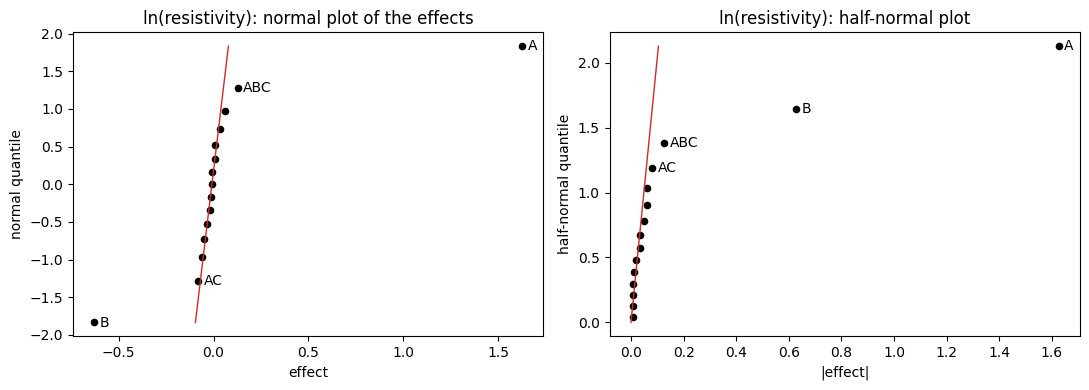

{'s0': 0.0542, 'PSE': 0.0533, 'ME': 0.1371, 'SME': 0.2784}
|effect| > ME : ['A', 'B']    |effect| > SME: ['A', 'B']
|effect| / PSE: {'A': 30.48, 'B': 11.78, 'ABC': 2.38, 'AC': 1.49, 'ABCD': 1.17, 'ABD': 1.12}

Box-Cox check, residual SS of the models A + B and A + B + AB for the scaled power transformation:
lambda =   1.0: SS_E(A + B) =  24.055,   SS_E(A + B + AB) =   5.758
lambda =   0.5: SS_E(A + B) =   6.650,   SS_E(A + B + AB) =   2.311
lambda =   0.0: SS_E(A + B) =   1.528,   SS_E(A + B + AB) =   1.424
lambda =  -0.5: SS_E(A + B) =   3.478,   SS_E(A + B + AB) =   1.629
lambda =  -1.0: SS_E(A + B) =  13.655,   SS_E(A + B + AB) =   2.780


In [45]:
# 6.36c: ln(y): effects, normal / half-normal plots, Lenth's method, Box-Cox check
p636["ln_y"] = np.log(p636["resistivity"])
t636l = effects_2k(p636, "ln_y", F4)
e636l = t636l["effect"].rename(lambda t: t.replace(":", ""))
display(t636l[["effect", "SS", "coef"]].round(4).T)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(e636l, n_label=4, ax=axes[0], title="ln(resistivity): normal plot of the effects")
effect_plot(e636l, half=True, n_label=4, ax=axes[1], title="ln(resistivity): half-normal plot")
plt.tight_layout(); plt.show()
L636l = lenth(e636l)
print({k: round(v, 4) for k, v in L636l.items()})
print("|effect| > ME :", list(e636l[e636l.abs() > L636l["ME"]].index), "   |effect| > SME:", list(e636l[e636l.abs() > L636l["SME"]].index))
print("|effect| / PSE:", (e636l.abs() / L636l["PSE"]).sort_values(ascending=False).round(2).head(6).to_dict())

gm = np.exp(p636["ln_y"].mean())
print("\nBox-Cox check, residual SS of the models A + B and A + B + AB for the scaled power transformation:")
for lam in [1, 0.5, 0, -0.5, -1]:
    y_lam = gm * p636["ln_y"] if lam == 0 else (p636["resistivity"]**lam - 1) / (lam * gm**(lam - 1))
    d = p636.assign(y=y_lam)
    print(f"lambda = {lam:5.1f}: SS_E(A + B) = {smf.ols('y ~ A + B', data=d).fit().ssr:7.3f},"
          f"   SS_E(A + B + AB) = {smf.ols('y ~ A + B + A:B', data=d).fit().ssr:7.3f}")

Only $A = 1.626$ and $B = -0.629$ leave the line; $AB = -0.049$ is now negligible ($0.9\,PSE$). Lenth: $PSE = 0.053$,
$ME = 0.137$, $SME = 0.278$. Box-Cox selects $\lambda = 0$: $SS_E$ of $A + B$ falls from 24.1 ($\lambda = 1$) to 1.53
($\lambda = 0$) and rises again, and the interaction then buys almost nothing (1.42). Tentative model for $\ln y$: $A + B$
with 13 df for error.

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,10.5721,10.5721,962.9454,0.0
B,1.0,1.5803,1.5803,143.9414,0.0
Residual,13.0,0.1427,0.0110,NaN,NaN


                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.1854      0.026     45.253      0.000       1.129       1.242
A              0.8129      0.026     31.031      0.000       0.756       0.869
B             -0.3143      0.026    -11.998      0.000      -0.371      -0.258
MS_E = 0.01098 (13 df), R2 = 0.9884, adj. R2 = 0.9866
AB added to the log model: {'F': 0.88, 'PR(>F)': 0.367}


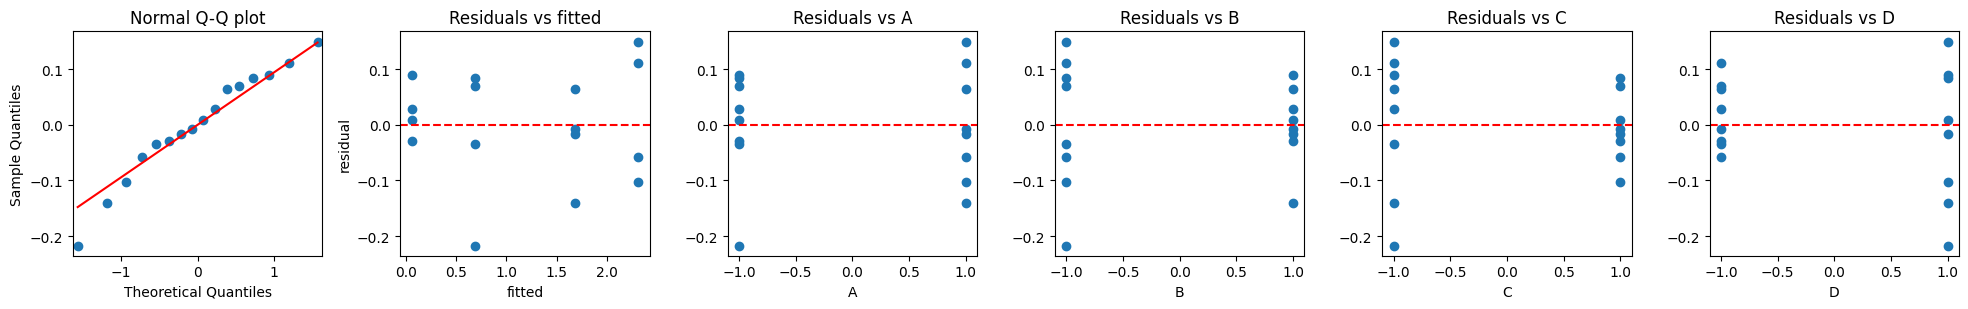

Shapiro-Wilk on residuals: ShapiroResult(statistic=0.9667947125870824, pvalue=0.7843979538937385)


mean    std
A  B               
-1 -1  0.662  0.138
    1  0.083  0.050
 1 -1  2.337  0.124
    1  1.659  0.085

In [46]:
# 6.36c (cont.): fit of ln(y) ~ A + B, test of the dropped interaction, residuals
m636l = smf.ols("ln_y ~ A + B", data=p636).fit()
display(anova_lm(m636l).round(4))
print(m636l.summary().tables[1])
print(f"MS_E = {m636l.mse_resid:.5f} ({m636l.df_resid:.0f} df), R2 = {m636l.rsquared:.4f}, adj. R2 = {m636l.rsquared_adj:.4f}")
print("AB added to the log model:", anova_lm(smf.ols("ln_y ~ A + B + A:B", data=p636).fit()).loc["A:B", ["F", "PR(>F)"]].round(3).to_dict())
residual_plots(m636l, p636, F4)
display(p636.groupby(["A", "B"])["ln_y"].agg(["mean", "std"]).round(3))

| Term | $SS$ | $F_0$ (1, 13 df) | $p$-value | Decision |
|---|---|---|---|---|
| $A$ | 10.572 | 962.9 | $< 0.0001$ | reject $H_0$ |
| $B$ | 1.580 | 143.9 | $< 0.0001$ | reject $H_0$ |

$AB$ is not needed ($F_0 = 0.88$, $p = 0.37$). The residuals are now homogeneous (cell sd 0.05 to 0.14 without trend), no
funnel, straight Q-Q plot ($W = 0.967$, $p = 0.78$), no pattern against $C$, $D$. The transformation stabilises the variance,
removes the interaction ($R^2$ from 0.974 to 0.988) and makes the effects multiplicative.

**(d) Prediction model in coded variables.** Fitted on the log scale and transformed back; $e^{\hat y_{\ln}}$ estimates the
median, not the mean.

In [47]:
# 6.36d: prediction equation in coded variables, back-transformation and a check against the observed cells
bl = m636l.params
print(f"ln(y_hat) = {bl['Intercept']:.4f} + {bl['A']:.4f} x1 {bl['B']:+.4f} x2")
print(f"y_hat = exp(ln y_hat) = {np.exp(bl['Intercept']):.3f} * {np.exp(bl['A']):.3f}^x1 * {np.exp(bl['B']):.3f}^x2")
print(f"A from -1 to +1 multiplies the resistivity by exp({2 * bl['A']:.3f}) = {np.exp(2 * bl['A']):.2f};"
      f" B from -1 to +1 by exp({2 * bl['B']:.3f}) = {np.exp(2 * bl['B']):.3f}")
pred = pd.DataFrame(list(itertools.product([-1, 1], repeat=2)), columns=["A", "B"])
pred["ln y_hat"] = m636l.predict(pred)
pred["y_hat = exp"] = np.exp(pred["ln y_hat"])
pred["observed geometric mean"] = np.exp(p636.groupby(["A", "B"])["ln_y"].mean().to_numpy())
pred["observed mean"] = p636.groupby(["A", "B"])["resistivity"].mean().to_numpy()
pred["raw-scale model"] = m636.predict(pred[["A", "B"]])
se_fit = np.sqrt(m636l.mse_resid * 3 / 16)              # 3 parameters, orthogonal design
t13 = stats.t.ppf(0.975, m636l.df_resid)
pred["95 % PI low"] = np.exp(pred["ln y_hat"] - t13 * np.sqrt(se_fit**2 + m636l.mse_resid))
pred["95 % PI high"] = np.exp(pred["ln y_hat"] + t13 * np.sqrt(se_fit**2 + m636l.mse_resid))
display(pred.round(3))

ln(y_hat) = 1.1854 + 0.8129 x1 -0.3143 x2
y_hat = exp(ln y_hat) = 3.272 * 2.254^x1 * 0.730^x2
A from -1 to +1 multiplies the resistivity by exp(1.626) = 5.08; B from -1 to +1 by exp(-0.629) = 0.533


,A,B,ln y_hat,y_hat = exp,observed geometric mean,observed mean,raw-scale model,95 % PI low,95 % PI high
0,-1,-1,0.687,1.987,1.939,1.953,1.953,1.553,2.543
1,-1,1,0.058,1.060,1.086,1.088,1.088,0.828,1.357
2,1,-1,2.313,10.100,10.353,10.412,10.412,7.892,12.926
3,1,1,1.684,5.387,5.256,5.270,5.270,4.209,6.894


$$\ln \hat y = 1.185 + 0.813\,x_1 - 0.314\,x_2, \qquad \hat y = 3.27 \cdot 2.25^{x_1} \cdot 0.73^{x_2}$$
($C$, $D$ do not enter). High $A$ multiplies the resistivity by $e^{1.626} = 5.1$, high $B$ divides it by $e^{0.629} = 1.9$,
independently; the raw-scale interaction was only the arithmetic of this multiplicative behaviour. The back-transformed
predictions (1.99, 1.06, 10.10, 5.39) match the observed geometric means within 3 %; the 95 % prediction intervals scale with
the level (factor 0.78 to 1.28).

**Conclusions (Problem 6.36)**

* Original scale: $A$, $B$, $AB$ active ($p < 0.0001$) but the residual spread grows with the mean, constant variance fails.
* $\ln(y)$ (Box-Cox $\lambda = 0$) removes the funnel and the interaction: $\ln \hat y = 1.185 + 0.813\,x_1 - 0.314\,x_2$,
  $R^2 = 0.988$, residuals normal and homogeneous.
* $\hat y = 3.27 \cdot 2.25^{x_1} \cdot 0.73^{x_2}$: high $A$ multiplies the resistivity by 5, high $B$ roughly halves it;
  $C$, $D$ inert.